# Problem Statement:

The healthcare industry faces challenges in identifying heart disease at an early stage due to increasing patient data and limitations of traditional diagnostic methods. There is a need for an intelligent system that can analyze medical data and accurately predict the risk of heart disease in patients.

This project aims to analyze heart disease data and develop a machine learning model that predicts the likelihood of heart disease based on medical attributes such as age, blood pressure, cholesterol, chest pain type, and heart rate. The system will help hospitals and healthcare professionals take preventive actions, improve early diagnosis, and reduce life-threatening situations.

# Importing Libraries:

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Loading Dataset:

In [2]:
labels = pd.read_csv("labels.csv")
values = pd.read_csv("values.csv")

In [3]:
data = pd.merge(values, labels, on="patient_id")

In [4]:
data

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,5qfar3,2,reversible_defect,125,4,2,1,0,254,0.2,1,67,163,0,1
176,2s2b1f,2,normal,180,4,0,0,1,327,3.4,0,55,117,1,1
177,nsd00i,2,reversible_defect,125,3,0,0,0,309,1.8,1,64,131,1,1
178,0xw93k,1,normal,124,3,2,1,0,255,0.0,1,48,175,0,0


# Domain Analysis:

The project belongs to the domain of Healthcare Analytics and Machine Learning. Healthcare analytics helps in analyzing patient data to identify patterns, trends, and risk factors related to cardiovascular diseases. Machine learning techniques are used to build predictive models that can assist healthcare professionals in identifying patients who are at high risk of heart disease.

* Important medical attributes available in the dataset include:

    * Age
    * Sex
    * Chest pain type
    * Resting blood pressure
    * Cholesterol level
    * Blood sugar level
    * ECG results
    * Maximum heart rate
    * Exercise-induced angina

* The target column in this project is heart_disease_present, which is used to identify whether a patient has heart disease or not.

* The dataset contains both numerical and categorical medical features that help analyze cardiovascular conditions.

* The prediction system helps hospitals identify high-risk patients at an early stage and take preventive measures before the disease becomes severe. It supports doctors in faster and more accurate decision-making and improves healthcare efficiency.

* Benefits of the System:
    * Early prediction of heart disease
    * Better patient monitoring
    * Reduced life-threatening situations
    * Improved healthcare decision-making
    * Increased patient awareness about cardiovascular health

# Exploratory Data Analysis (EDA):

### 1. Initial Data Inspection:

In [5]:
data.head()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [6]:
data.tail()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
175,5qfar3,2,reversible_defect,125,4,2,1,0,254,0.2,1,67,163,0,1
176,2s2b1f,2,normal,180,4,0,0,1,327,3.4,0,55,117,1,1
177,nsd00i,2,reversible_defect,125,3,0,0,0,309,1.8,1,64,131,1,1
178,0xw93k,1,normal,124,3,2,1,0,255,0.0,1,48,175,0,0
179,2nx10r,1,normal,160,3,1,0,0,201,0.0,0,54,163,0,0


### 2. Data Overview/Structure:

In [7]:
data.shape

(180, 15)

In [8]:
data.columns

Index(['patient_id', 'slope_of_peak_exercise_st_segment', 'thal',
       'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age',
       'max_heart_rate_achieved', 'exercise_induced_angina',
       'heart_disease_present'],
      dtype='object')

In [9]:
data.dtypes

patient_id                               object
slope_of_peak_exercise_st_segment         int64
thal                                     object
resting_blood_pressure                    int64
chest_pain_type                           int64
num_major_vessels                         int64
fasting_blood_sugar_gt_120_mg_per_dl      int64
resting_ekg_results                       int64
serum_cholesterol_mg_per_dl               int64
oldpeak_eq_st_depression                float64
sex                                       int64
age                                       int64
max_heart_rate_achieved                   int64
exercise_induced_angina                   int64
heart_disease_present                     int64
dtype: object

In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age                

### 3. Data Quality Checks:

In [11]:
data.isnull().sum()

patient_id                              0
slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64

In [12]:
data.duplicated().sum()

np.int64(0)

### 4. Statistical Summary:

In [13]:
data.describe()

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,1.550000,131.311111,3.155556,0.694444,0.161111,1.050000,249.211111,1.010000,0.688889,54.811111,149.483333,0.316667,0.444444
std,0.618838,17.010443,0.938454,0.969347,0.368659,0.998742,52.717969,1.121357,0.464239,9.334737,22.063513,0.466474,0.498290
min,1.000000,94.000000,1.000000,0.000000,0.000000,0.000000,126.000000,0.000000,0.000000,29.000000,96.000000,0.000000,0.000000
25%,1.000000,120.000000,3.000000,0.000000,0.000000,0.000000,213.750000,0.000000,0.000000,48.000000,132.000000,0.000000,0.000000
50%,1.000000,130.000000,3.000000,0.000000,0.000000,2.000000,245.500000,0.800000,1.000000,55.000000,152.000000,0.000000,0.000000
75%,2.000000,140.000000,4.000000,1.000000,0.000000,2.000000,281.250000,1.600000,1.000000,62.000000,166.250000,1.000000,1.000000
max,3.000000,180.000000,4.000000,3.000000,1.000000,2.000000,564.000000,6.200000,1.000000,77.000000,202.000000,1.000000,1.000000


In [14]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
slope_of_peak_exercise_st_segment,180.0,1.550000,0.618838,1.0,1.00,1.0,2.00,3.0
resting_blood_pressure,180.0,131.311111,17.010443,94.0,120.00,130.0,140.00,180.0
chest_pain_type,180.0,3.155556,0.938454,1.0,3.00,3.0,4.00,4.0
num_major_vessels,180.0,0.694444,0.969347,0.0,0.00,0.0,1.00,3.0
fasting_blood_sugar_gt_120_mg_per_dl,180.0,0.161111,0.368659,0.0,0.00,0.0,0.00,1.0
resting_ekg_results,180.0,1.050000,0.998742,0.0,0.00,2.0,2.00,2.0
serum_cholesterol_mg_per_dl,180.0,249.211111,52.717969,126.0,213.75,245.5,281.25,564.0
oldpeak_eq_st_depression,180.0,1.010000,1.121357,0.0,0.00,0.8,1.60,6.2
sex,180.0,0.688889,0.464239,0.0,0.00,1.0,1.00,1.0
age,180.0,54.811111,9.334737,29.0,48.00,55.0,62.00,77.0


### 5. Target Variable Analysis:

In [15]:
data['heart_disease_present'].value_counts()

heart_disease_present
0    100
1     80
Name: count, dtype: int64

<Axes: xlabel='heart_disease_present', ylabel='count'>

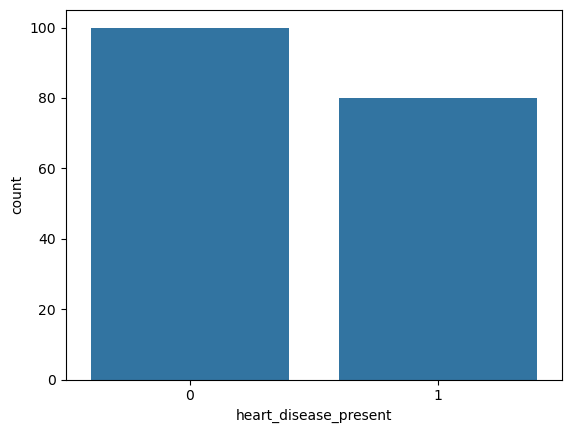

In [16]:
sns.countplot(x='heart_disease_present', data=data)

#### Insights:
The dataset was found to be clean, with no missing or duplicate values, ensuring better data quality and reliability for analysis. The dataset structure and data types were verified successfully before further processing. 

In the target variable analysis, it was observed that approximately 100 individuals do not have heart disease, while around 80 individuals have heart disease. This indicates that the dataset is relatively balanced, which is beneficial for building a reliable classification model and helps reduce bias toward any particular class.


### 6. Separating Numerical and Categorical Features:

In [17]:
num_cols = data.select_dtypes(include=['int64', 'float64']).columns

In [18]:
cat_cols = data.select_dtypes(include=['object']).columns

### 7. Univariate Analysis For Numerical Features:
  * Visualizing the shape of the distribution
  * Compact summary with emphasis on spread and outliers

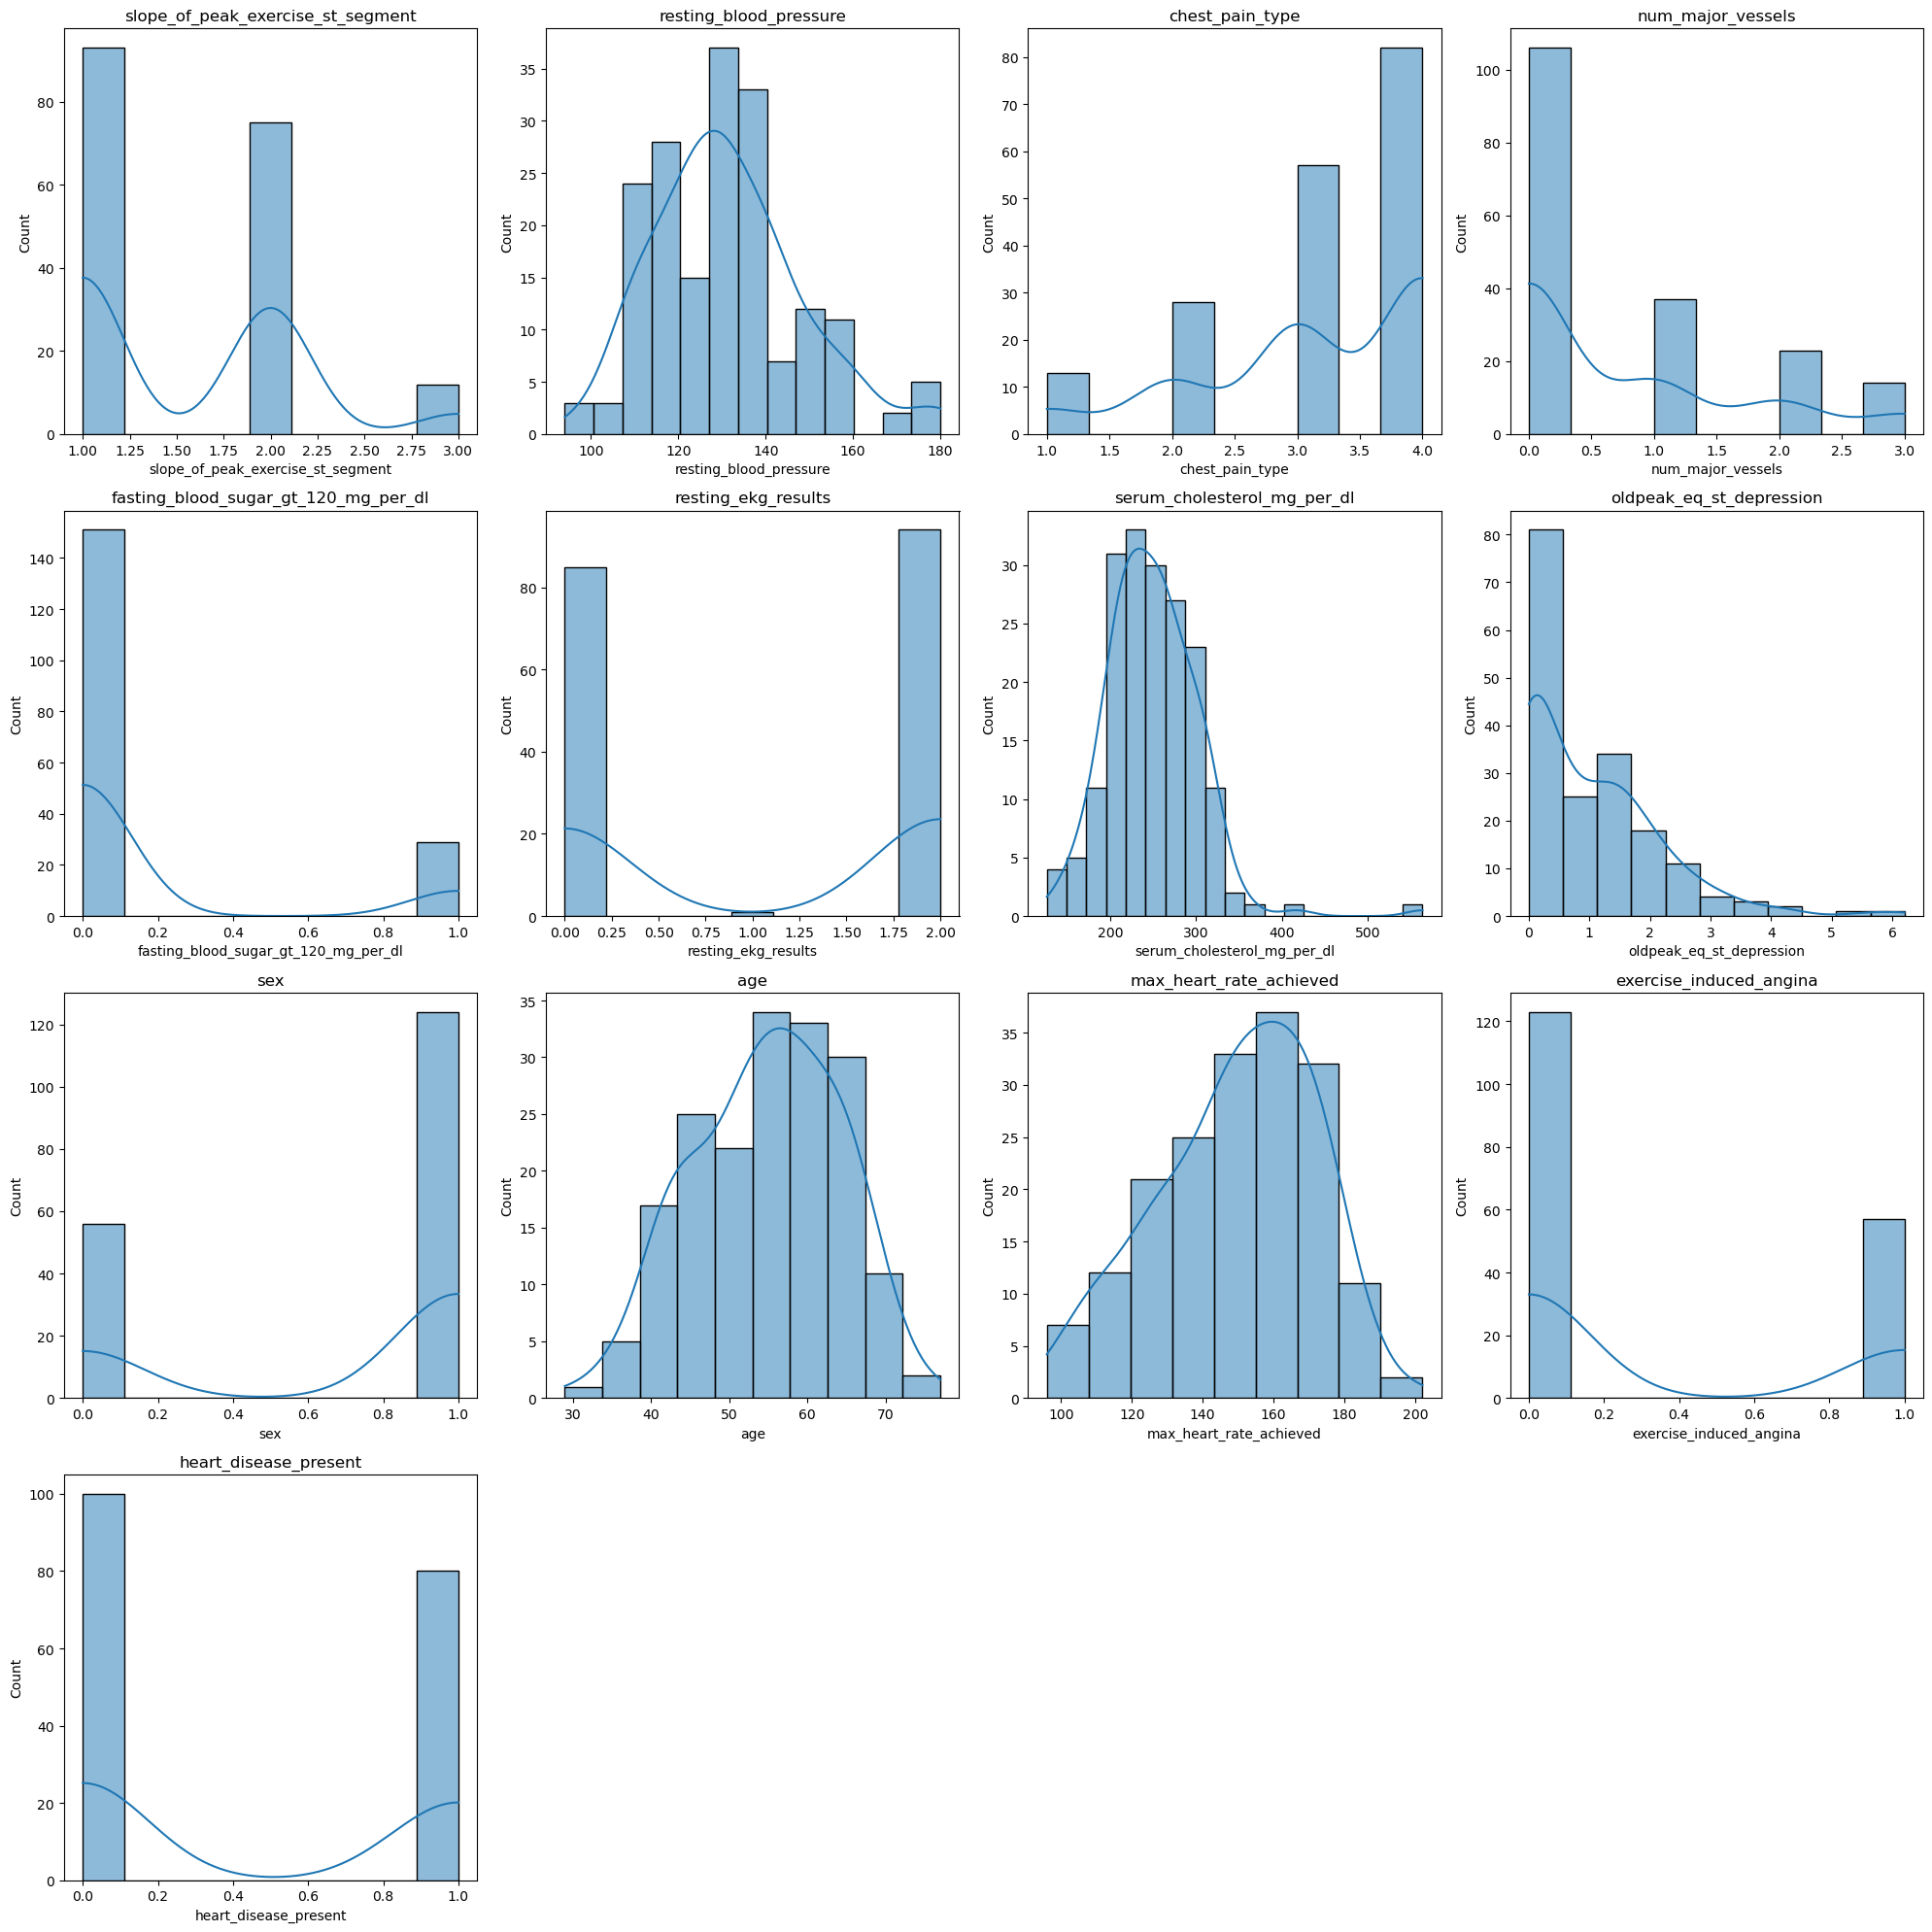

In [19]:
import math

cols = 4
rows = math.ceil(len(num_cols) / cols)

plt.figure(figsize=(20, 5 * rows))

for i, col in enumerate(num_cols, 1):
    plt.subplot(rows, cols, i)
    sns.histplot(data[col], kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

#### Insights:
* Some numerical features are positively skewed and some are negatively skewed, indicating non-normal distribution.

* A few features show approximately normal distribution, suggesting stable data.

* Presence of extreme values suggests potential outliers in the dataset.

* Skewed features may require transformation (e.g., log transformation).

* Outliers may need to be handled to prevent bias in modeling.

In [20]:
skewness = data[num_cols].skew().sort_values(ascending=False)
skewness

fasting_blood_sugar_gt_120_mg_per_dl    1.859153
oldpeak_eq_st_depression                1.507412
serum_cholesterol_mg_per_dl             1.273932
num_major_vessels                       1.167999
exercise_induced_angina                 0.794871
slope_of_peak_exercise_st_segment       0.666150
resting_blood_pressure                  0.657080
heart_disease_present                   0.225490
resting_ekg_results                    -0.100967
age                                    -0.199166
max_heart_rate_achieved                -0.393705
sex                                    -0.822900
chest_pain_type                        -0.849258
dtype: float64

In [21]:
skewed_cols = skewness[skewness > 1].index
skewed_cols

Index(['fasting_blood_sugar_gt_120_mg_per_dl', 'oldpeak_eq_st_depression',
       'serum_cholesterol_mg_per_dl', 'num_major_vessels'],
      dtype='object')

In [22]:
skewed_cols = ['serum_cholesterol_mg_per_dl',
               'oldpeak_eq_st_depression']

for col in skewed_cols:
    data[col] = np.log1p(data[col])

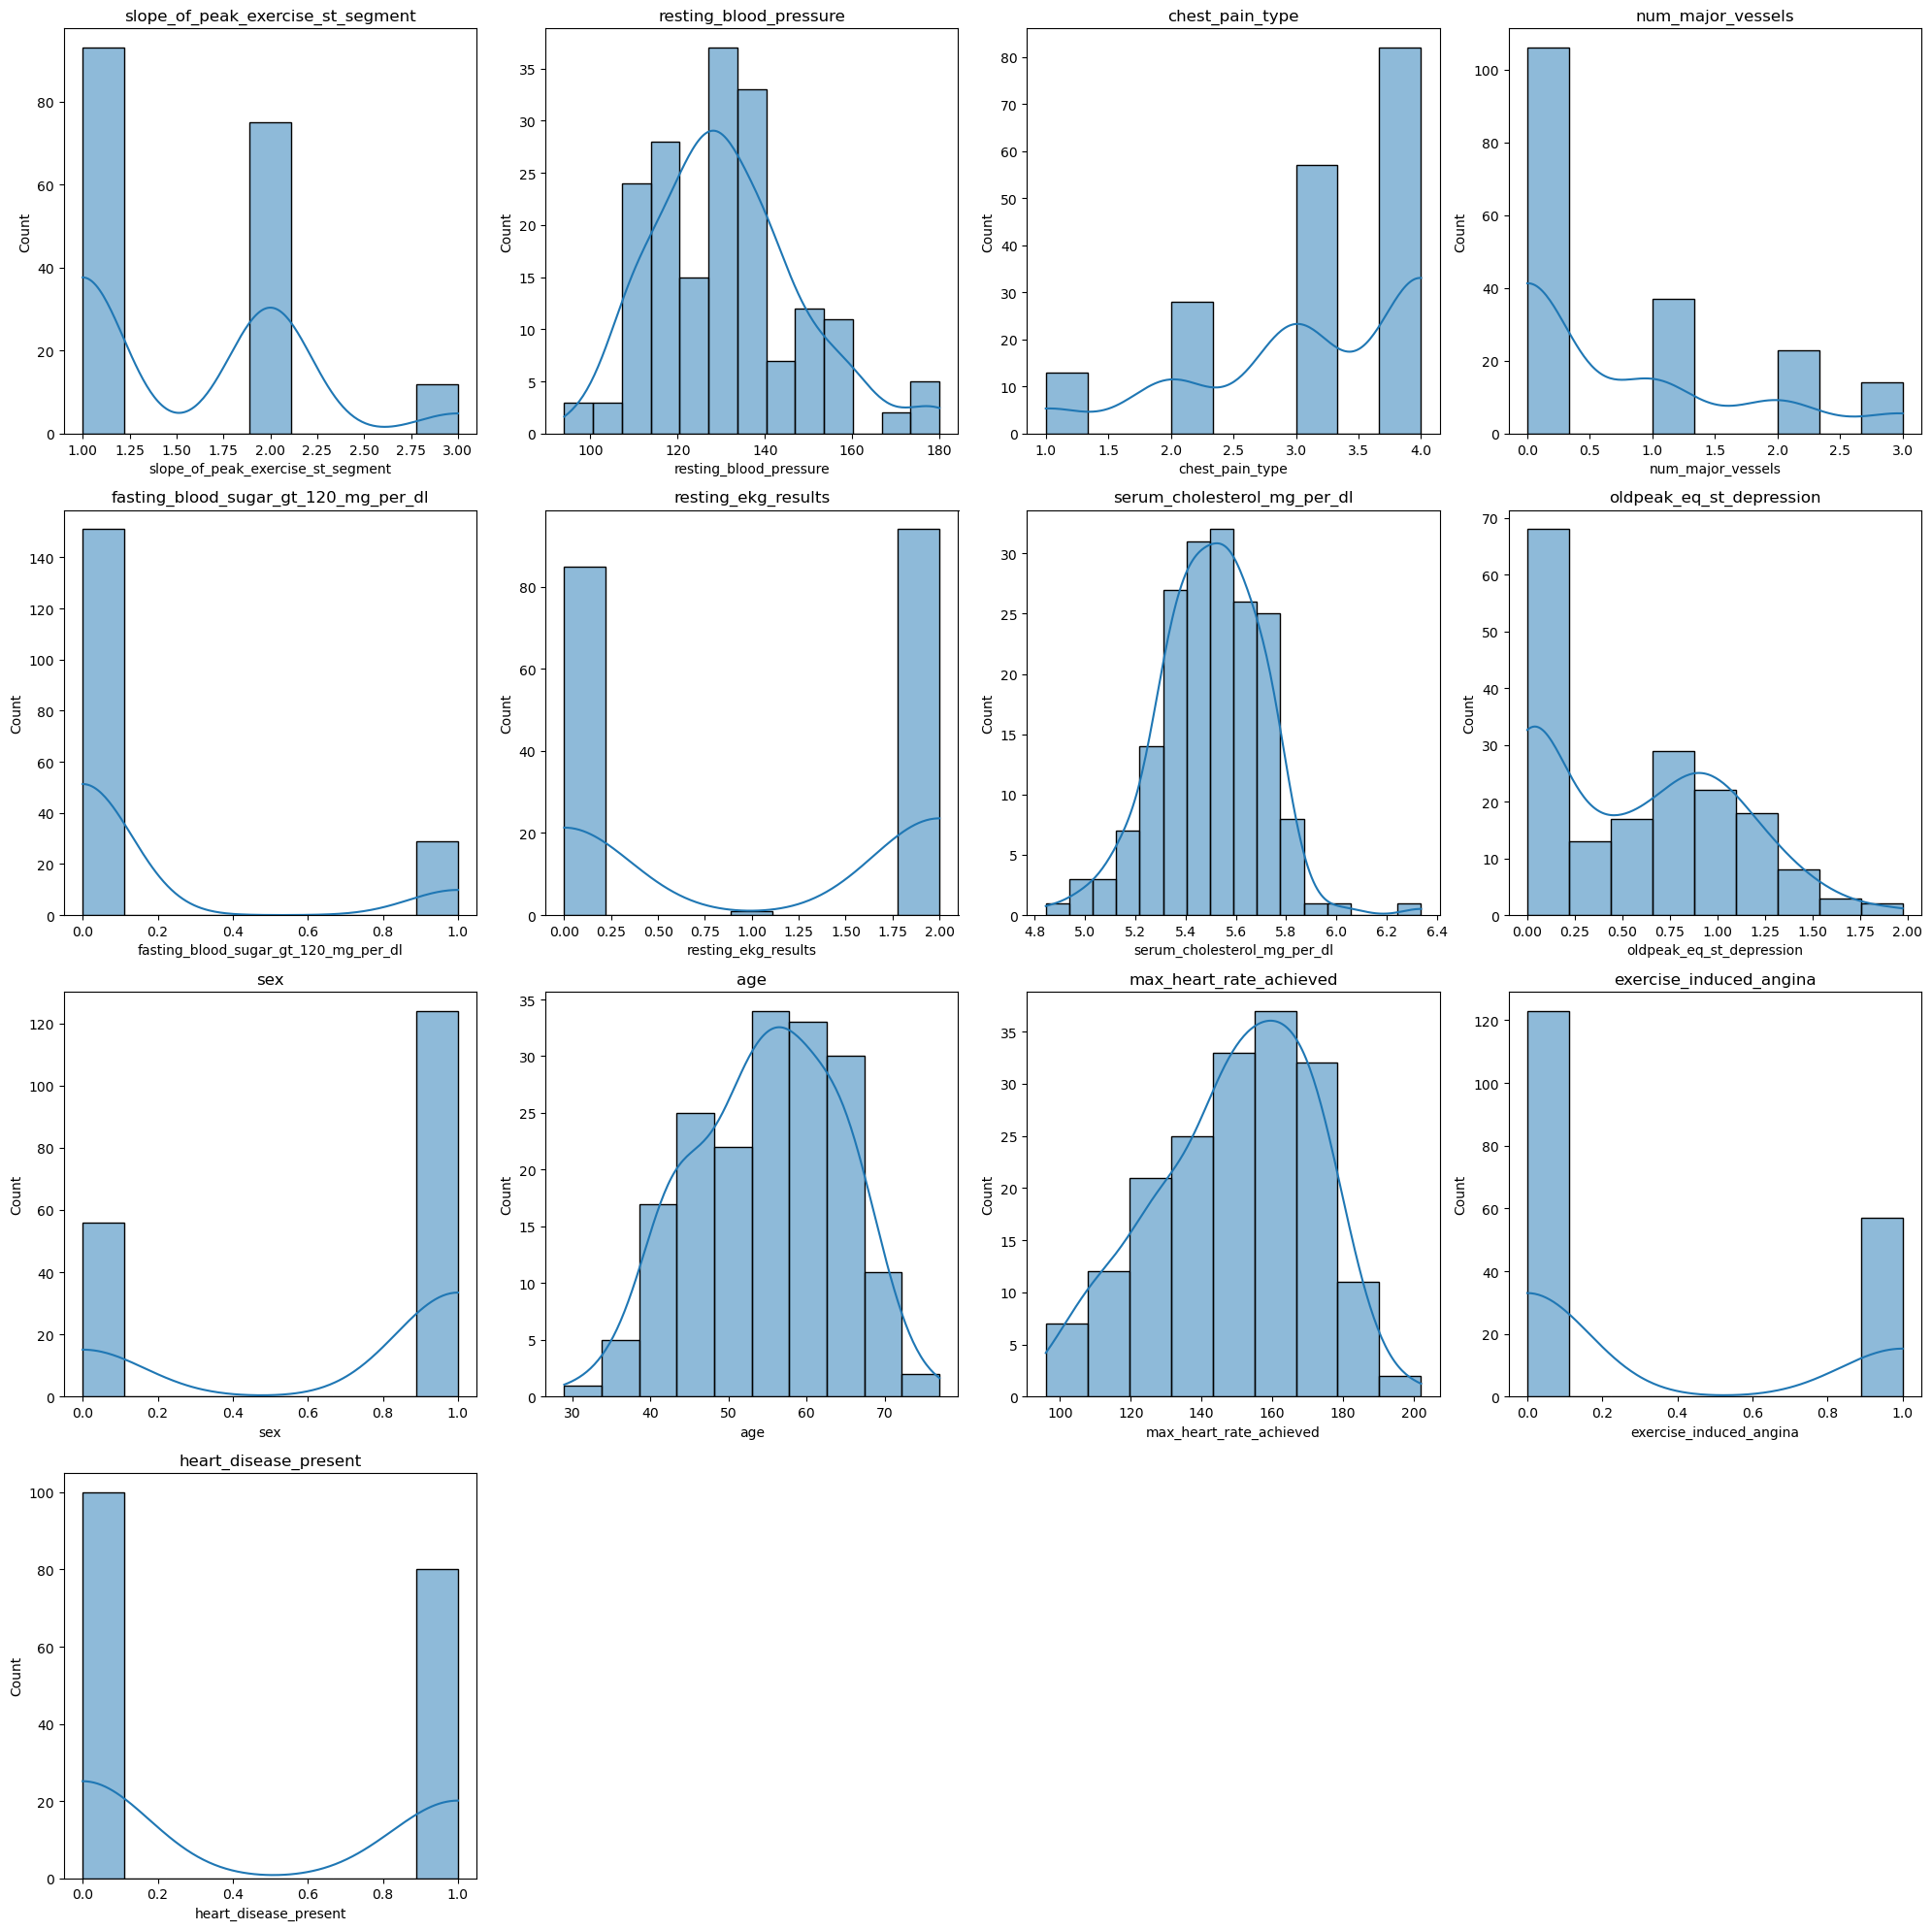

In [23]:
cols = 4
rows = math.ceil(len(num_cols) / cols)

plt.figure(figsize=(20, 5 * rows))

for i, col in enumerate(num_cols, 1):
    plt.subplot(rows, cols, i)
    sns.histplot(data[col], kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

### Insights:
Skewness analysis revealed that features such as serum cholesterol and oldpeak were highly positively skewed, so log transformation was applied to improve their distribution and reduce the effect of extreme values. However, fasting blood sugar and number of major vessels were not transformed because they represent binary and discrete count-based medical features. Applying log transformation to such variables could distort their original medical interpretation and may not provide meaningful improvement for model performance.

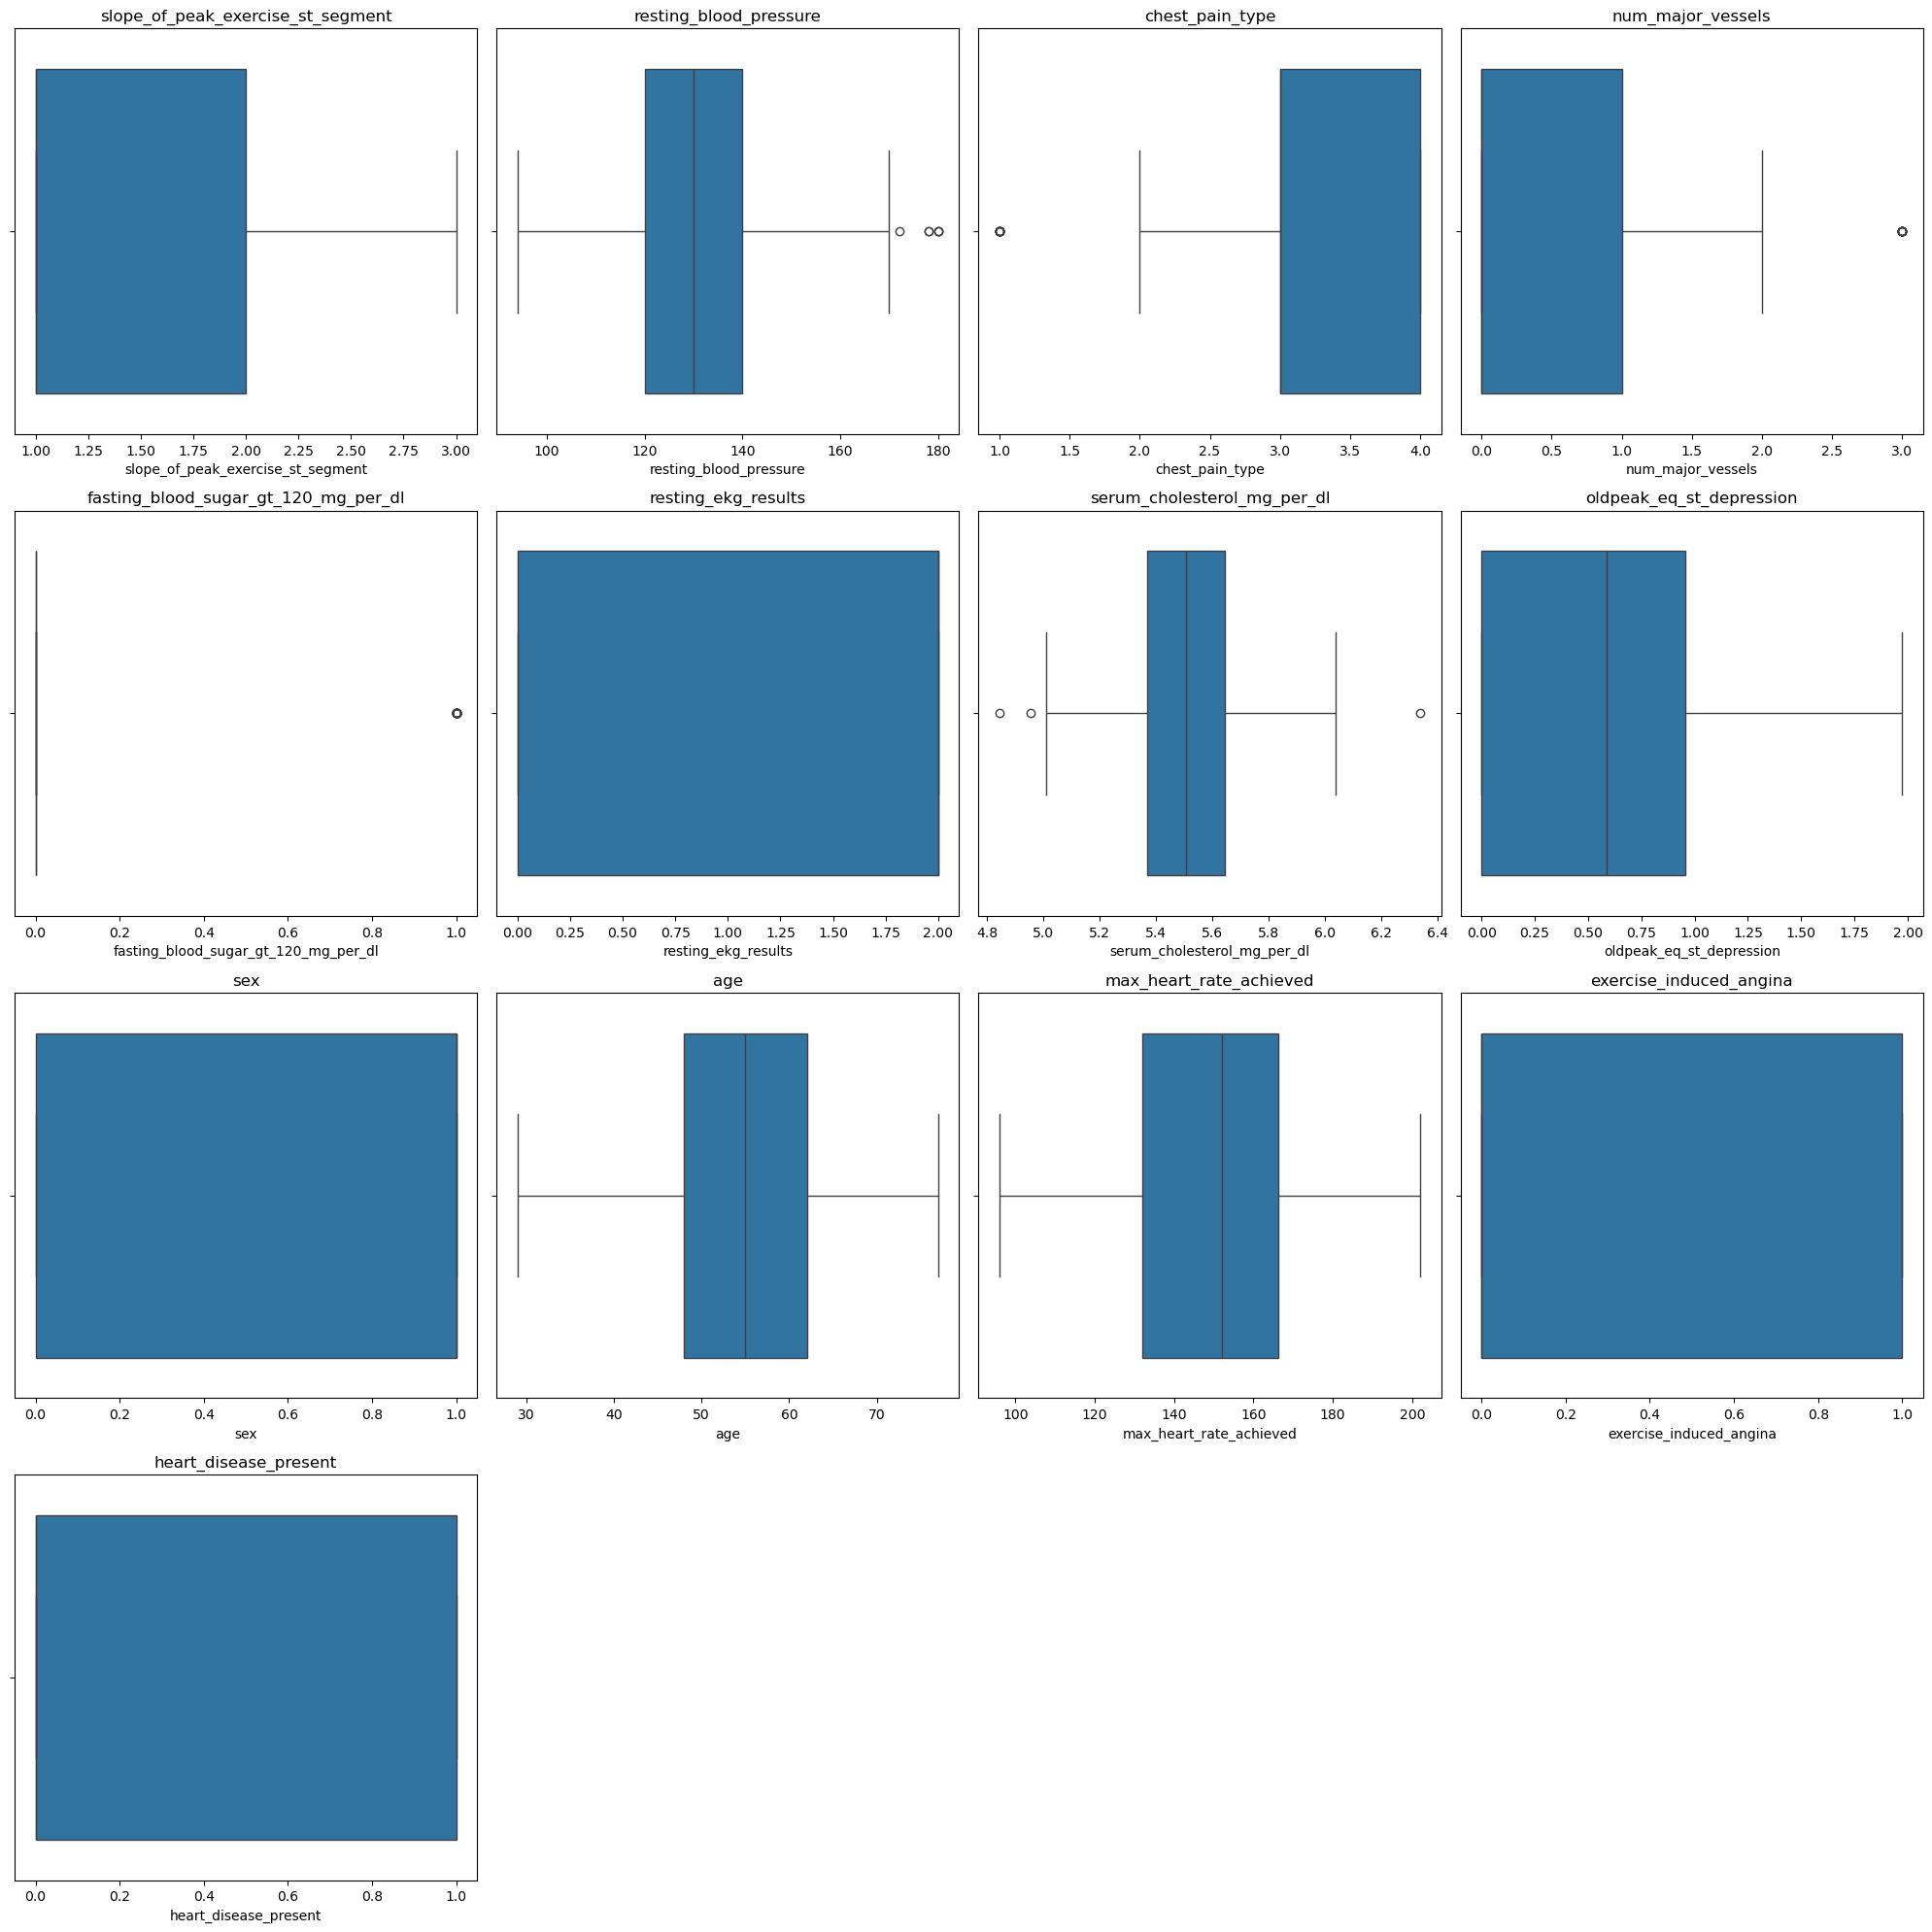

In [24]:
cols = 4
rows = math.ceil(len(num_cols) / cols)

plt.figure(figsize=(20, 5 * rows))

for i, col in enumerate(num_cols, 1):
    plt.subplot(rows, cols, i)
    sns.boxplot(x=data[col])
    plt.title(col)

plt.tight_layout()
plt.show()

#### Insights:
Boxplots were used to analyze the distribution and spread of numerical features in the heart disease dataset. The analysis revealed the presence of outliers in features such as serum cholesterol, resting blood pressure, and oldpeak, indicating extreme medical values in some patients. Features like age and maximum heart rate showed a comparatively balanced distribution with fewer extreme observations. 

Since this is a medical dataset, these outliers may represent clinically important cases rather than errors, so they were carefully examined before deciding on any preprocessing steps.

### 8. Bivariate Analysis For Numerical Features:
* Shows relationship between feature and target variable.
* shows spread and concentration of values.

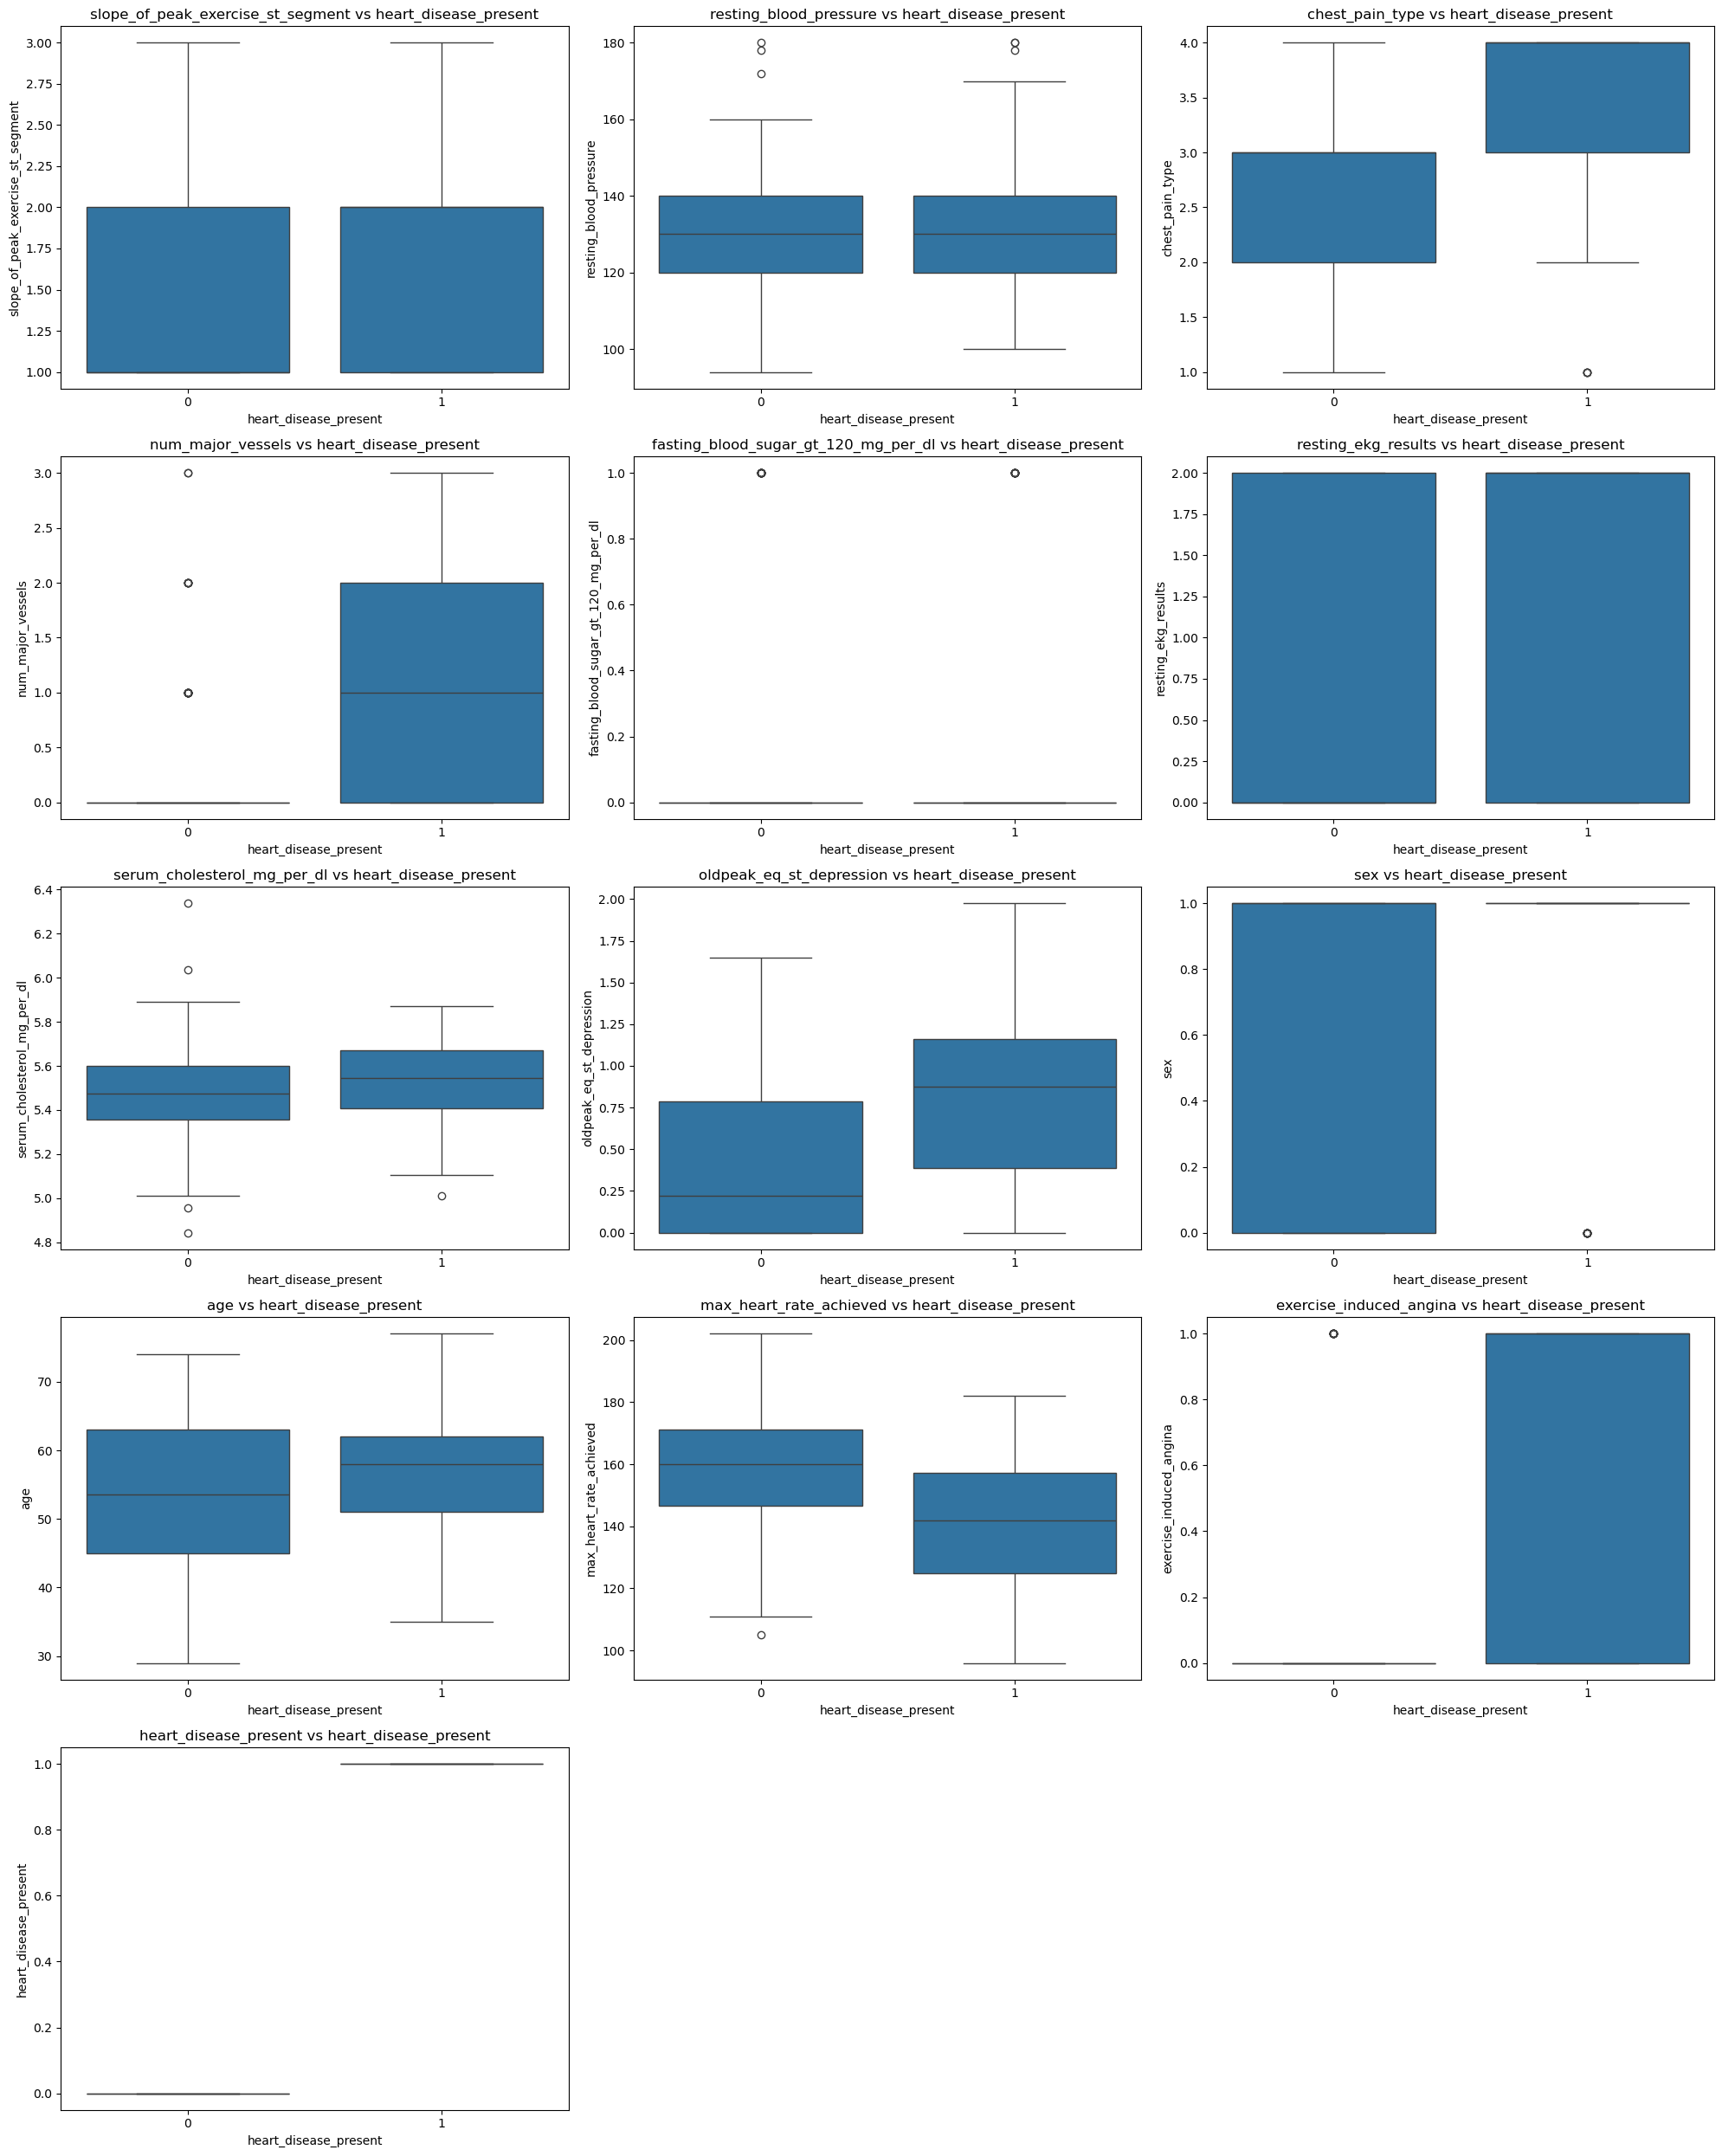

In [25]:
cols = 3
rows = math.ceil(len(num_cols) / cols)

plt.figure(figsize=(20,5 * rows))

for i, col in enumerate(num_cols, 1):
    plt.subplot(rows, cols, i)
    sns.boxplot(x='heart_disease_present', y=col, data=data)
    plt.title(f"{col} vs heart_disease_present")

plt.tight_layout()
plt.show()

#### Insights:
* Boxplots were used to compare numerical features between patients with and without heart disease.

* Patients with heart disease generally showed higher cholesterol levels and greater ST depression values.

* Older individuals appeared to have a higher risk of heart disease compared to younger patients.

* Differences in maximum heart rate achieved were observed between the two target classes.

* The analysis indicated that several numerical features may play an important role in predicting heart disease.

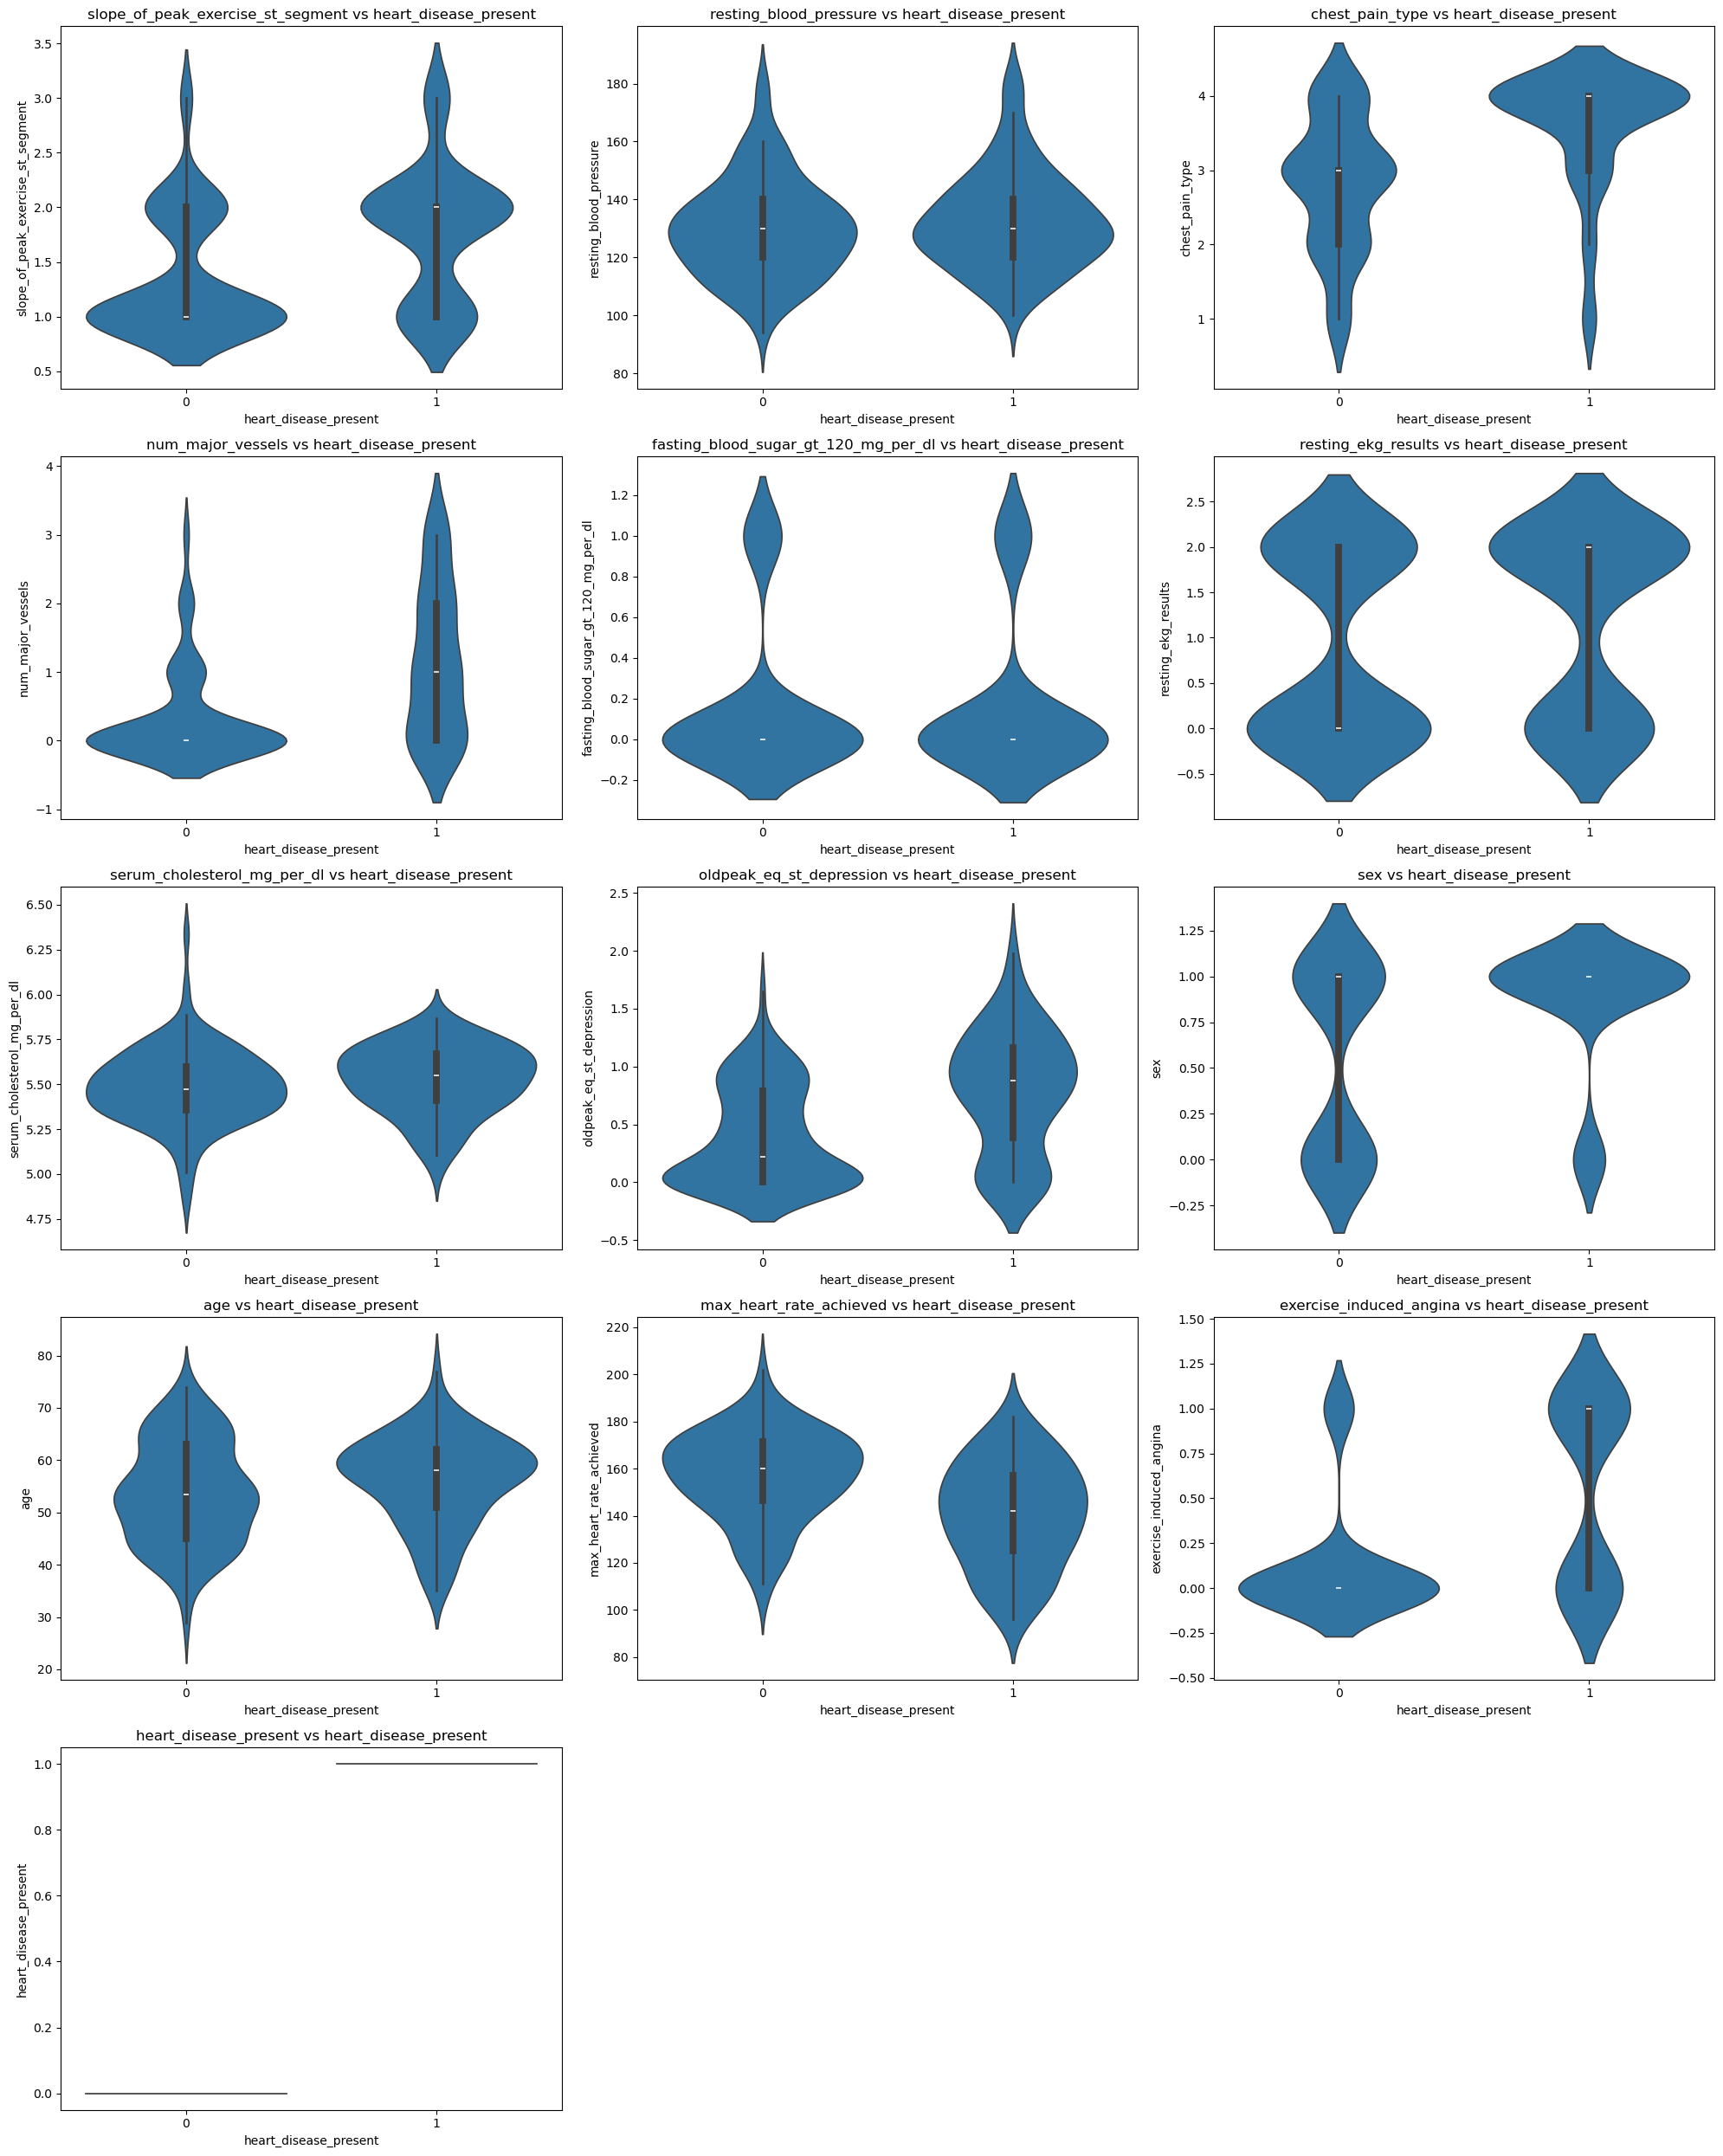

In [26]:
cols = 3
rows = math.ceil(len(num_cols) / cols)

plt.figure(figsize=(20,5 * rows))

for i, col in enumerate(num_cols, 1):
    plt.subplot(rows, cols, i)
    sns.violinplot(x='heart_disease_present', y=col, data=data)
    plt.title(f"{col} vs heart_disease_present")

plt.tight_layout()
plt.show()

#### Insights:
* Violin plots were used to analyze the distribution and density of numerical features across heart disease classes.

* The plots helped visualize the spread and concentration of values within each group.

* Features such as cholesterol, age, and oldpeak showed noticeable differences in distribution between patients with and without heart disease.

* Some overlap between the two classes was also observed, indicating shared characteristics among patients.

* The analysis highlighted the potential significance of several medical attributes in heart disease prediction.

### 9. Multivariate Analysis For Numerical Features:
* Shows relationships among multiple numerical features together.

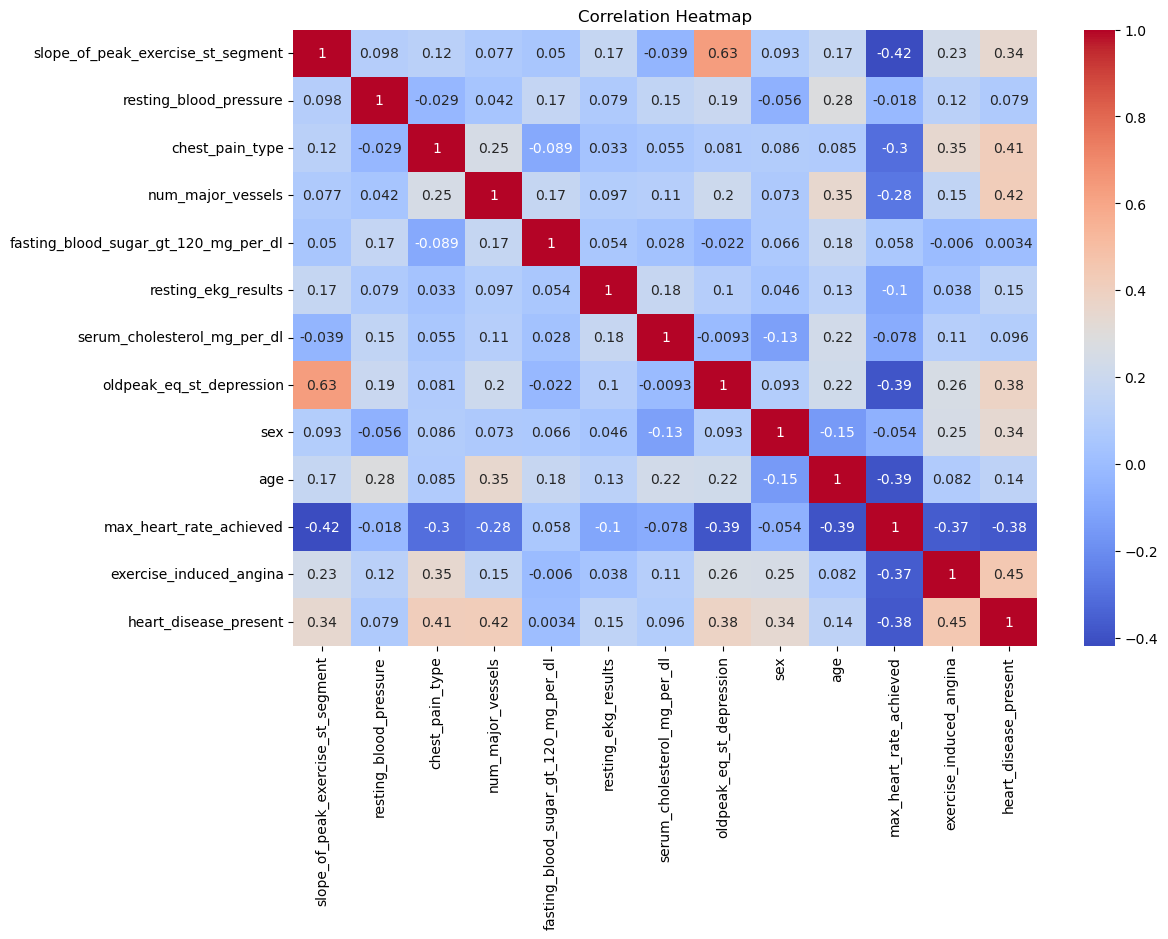

In [27]:
plt.figure(figsize=(12,8))
sns.heatmap(data.corr(numeric_only=True),
            annot=True,
            cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

#### Insights:
* The correlation heatmap was used to examine relationships among multiple medical features and the target variable in the heart disease dataset.

* A moderate relationship was observed between age and serum cholesterol levels, indicating that cholesterol may vary with increasing age in some patients.

* Resting blood pressure showed an association with heart disease presence, suggesting its potential importance as a cardiovascular risk factor.

* Maximum heart rate achieved and oldpeak demonstrated an inverse relationship, where patients with lower heart rates tended to show higher ST depression values during exercise.

* A noticeable relationship was also observed between oldpeak and the slope of peak exercise ST segment, indicating that exercise-related cardiac measurements are interconnected.

* The heatmap further helped identify feature-feature relationships and possible multicollinearity, providing useful insights before model building.


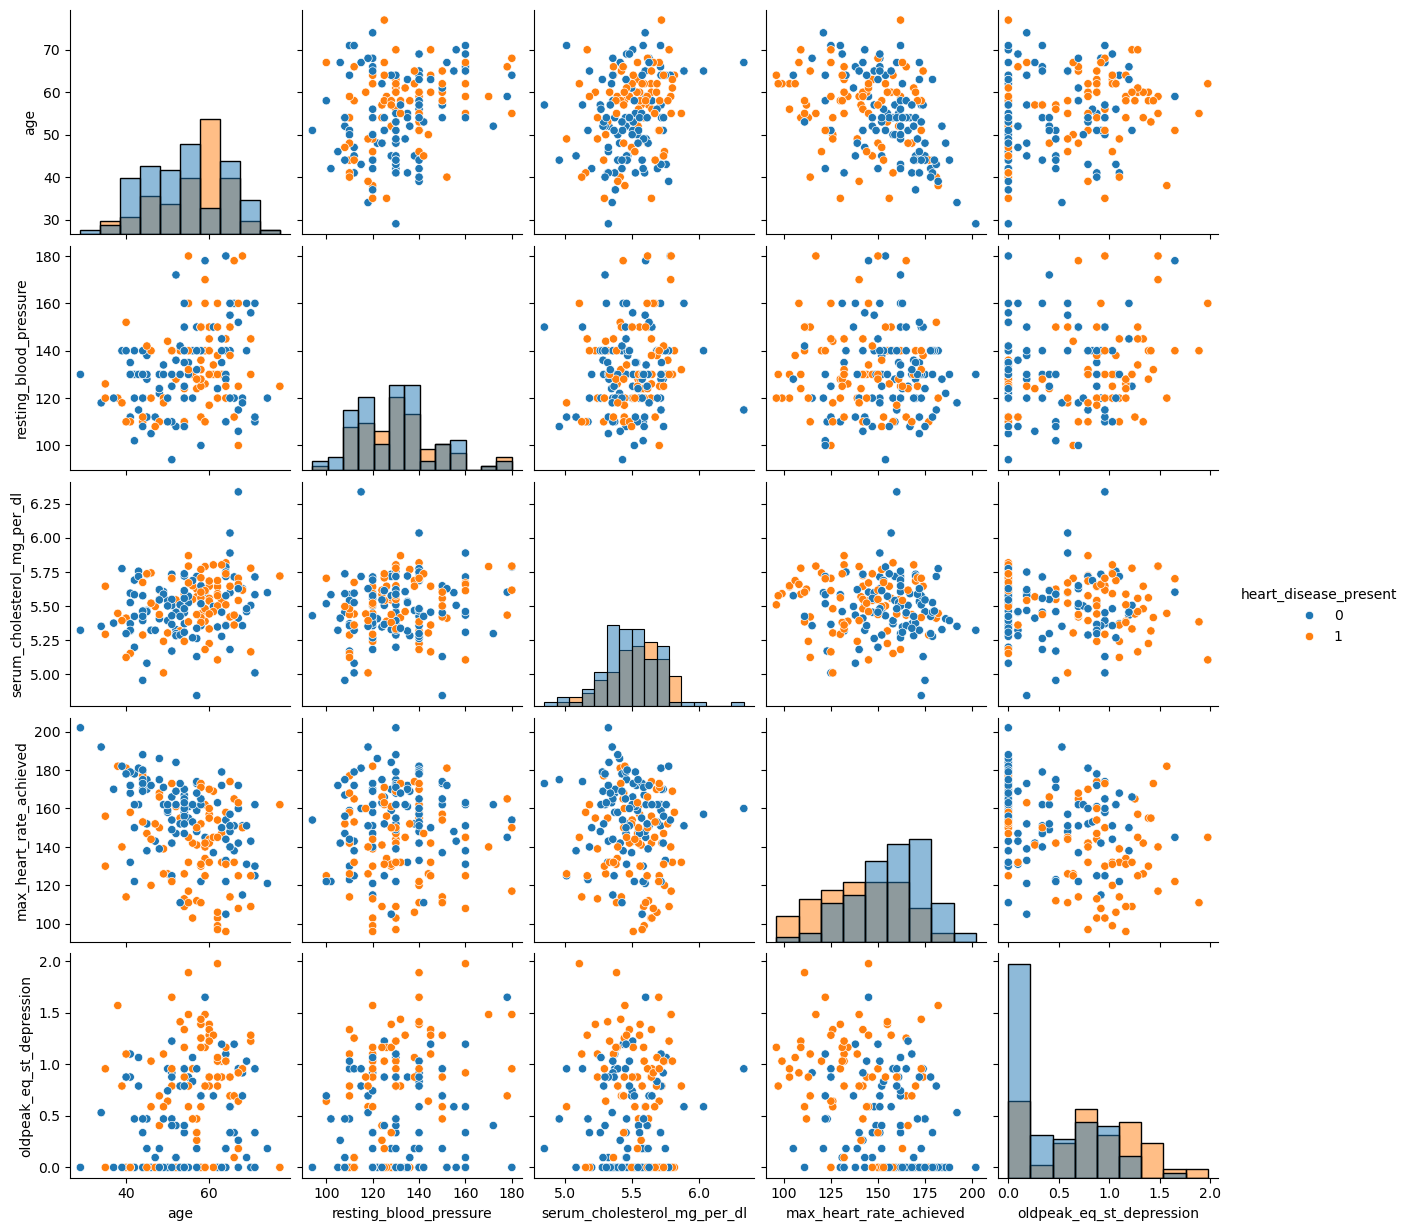

In [28]:
pair_cols = [
    'age',
    'resting_blood_pressure',
    'serum_cholesterol_mg_per_dl',
    'max_heart_rate_achieved',
    'oldpeak_eq_st_depression',
    'heart_disease_present'
]

sns.pairplot(
    data[pair_cols],
    hue='heart_disease_present',
    diag_kind='hist'
)

plt.show()

#### Insights:
* Pairplots were used to visualize relationships between important numerical features and heart disease presence.

* The analysis showed that older individuals appeared to have a higher likelihood of heart disease compared to younger patients.

* Serum cholesterol and resting blood pressure displayed variations across patients with and without heart disease, indicating their potential influence on cardiovascular health.

* Maximum heart rate achieved showed noticeable differences between the two target classes, suggesting its importance in distinguishing patients with heart disease.

* Oldpeak values tended to be higher among patients with heart disease, reflecting greater exercise-induced ST depression in affected individuals.

* The pairplot also helped identify patterns, feature interactions, and overlapping distributions between the two classes, providing a deeper understanding of the dataset before model building.


### 10. Univariate Analysis For Categorical Features:
* Shows distribution of each categorical feature individually.

In [29]:
cat_cols = [
    'slope_of_peak_exercise_st_segment',
    'chest_pain_type',
    'fasting_blood_sugar_gt_120_mg_per_dl',
    'resting_ekg_results',
    'sex',
    'exercise_induced_angina'
]

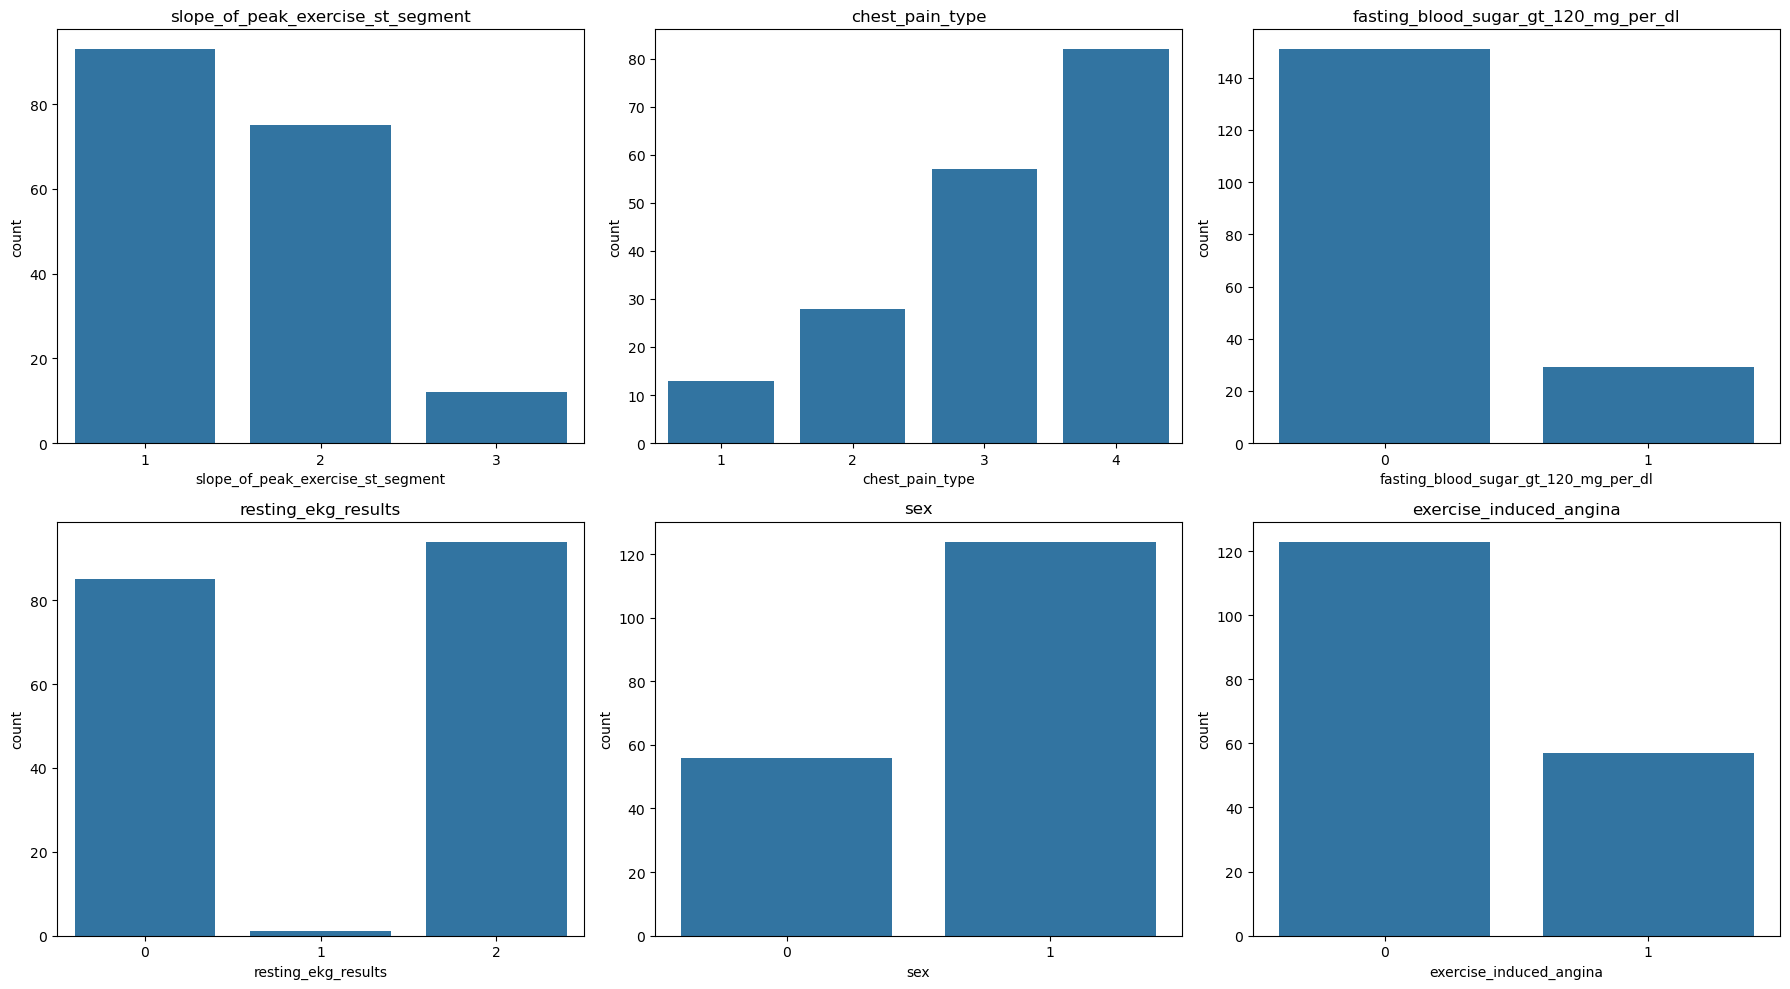

In [30]:
cols = 3
rows = math.ceil(len(cat_cols) / cols)

plt.figure(figsize=(18, 5 * rows))

for i, col in enumerate(cat_cols, 1):
    plt.subplot(rows, cols, i)
    sns.countplot(x=data[col])
    plt.title(col)

plt.tight_layout()
plt.show()

#### Insights:
* Countplots were used to analyze the distribution of categorical features in the heart disease dataset.

* The analysis helped identify the frequency of different medical categories and patient characteristics.

* Variations were observed in features such as chest pain type, exercise-induced angina, and resting ECG results, indicating diverse cardiovascular conditions among patients.

* The dataset also showed differences in gender distribution and fasting blood sugar categories.

* This analysis provided a clearer understanding of categorical feature patterns before further preprocessing and model building.

In [31]:
for col in cat_cols:
    print(data[col].value_counts())
    print("-" * 40)

slope_of_peak_exercise_st_segment
1    93
2    75
3    12
Name: count, dtype: int64
----------------------------------------
chest_pain_type
4    82
3    57
2    28
1    13
Name: count, dtype: int64
----------------------------------------
fasting_blood_sugar_gt_120_mg_per_dl
0    151
1     29
Name: count, dtype: int64
----------------------------------------
resting_ekg_results
2    94
0    85
1     1
Name: count, dtype: int64
----------------------------------------
sex
1    124
0     56
Name: count, dtype: int64
----------------------------------------
exercise_induced_angina
0    123
1     57
Name: count, dtype: int64
----------------------------------------


#### Insights:
Frequency analysis of categorical variables helped identify the most common patient and medical categories in the dataset. Countplots and value counts provided a clear understanding of category distribution, which is useful for detecting class imbalance and understanding patient characteristics before model development.

### 11. Bivariate Analysis of Categorical Features:
* Shows relationship between feature and target variable.

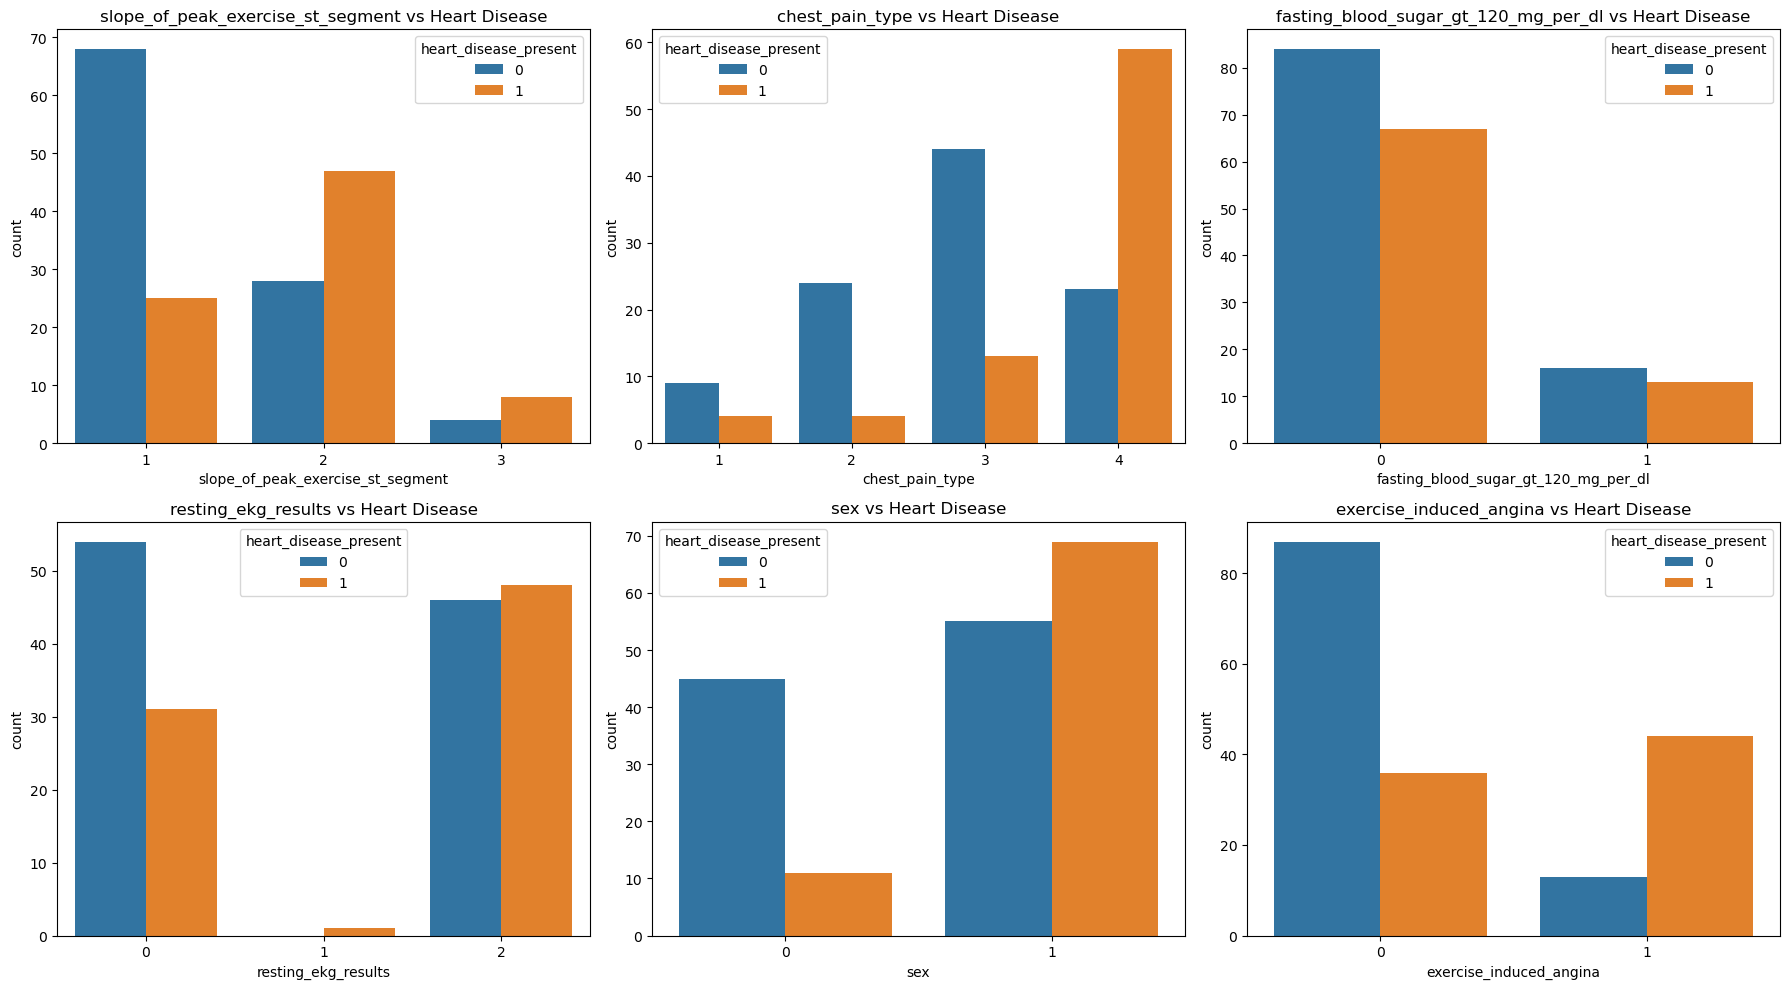

In [32]:
cols = 3
rows = math.ceil(len(cat_cols) / cols)

plt.figure(figsize=(18, 5 * rows))

for i, col in enumerate(cat_cols, 1):
    plt.subplot(rows, cols, i)
    sns.countplot(x=data[col],
                  hue=data['heart_disease_present'])
    
    plt.title(f"{col} vs Heart Disease")

plt.tight_layout()
plt.show()

#### Insights:
* Bivariate analysis of categorical features was performed using countplots with the target variable.

* The analysis helped compare category distributions between patients with and without heart disease.

* Certain chest pain types and exercise-induced angina categories appeared more frequently among patients with heart disease.

* Differences were also observed across gender and resting ECG result categories, indicating their possible influence on heart disease prediction.

* This analysis provided valuable insights into the relationship between categorical medical features and heart disease presence.

In [33]:
for col in cat_cols:
    print(pd.crosstab(
        data[col],
        data['heart_disease_present'],
        normalize='index'
    ))
    
    print("-" * 50)

heart_disease_present                     0         1
slope_of_peak_exercise_st_segment                    
1                                  0.731183  0.268817
2                                  0.373333  0.626667
3                                  0.333333  0.666667
--------------------------------------------------
heart_disease_present         0         1
chest_pain_type                          
1                      0.692308  0.307692
2                      0.857143  0.142857
3                      0.771930  0.228070
4                      0.280488  0.719512
--------------------------------------------------
heart_disease_present                        0         1
fasting_blood_sugar_gt_120_mg_per_dl                    
0                                     0.556291  0.443709
1                                     0.551724  0.448276
--------------------------------------------------
heart_disease_present         0         1
resting_ekg_results                      
0            

#### Insights:
Crosstab analysis was used to examine the proportion of heart disease cases across different categorical feature groups. This helped identify categories with a higher occurrence of heart disease and provided a clearer understanding of how categorical medical attributes relate to the target variable.

### 12. Multivariate Analysis of Categorical Features:
* Shows multiple categorical features together and their relationship with the target variable.

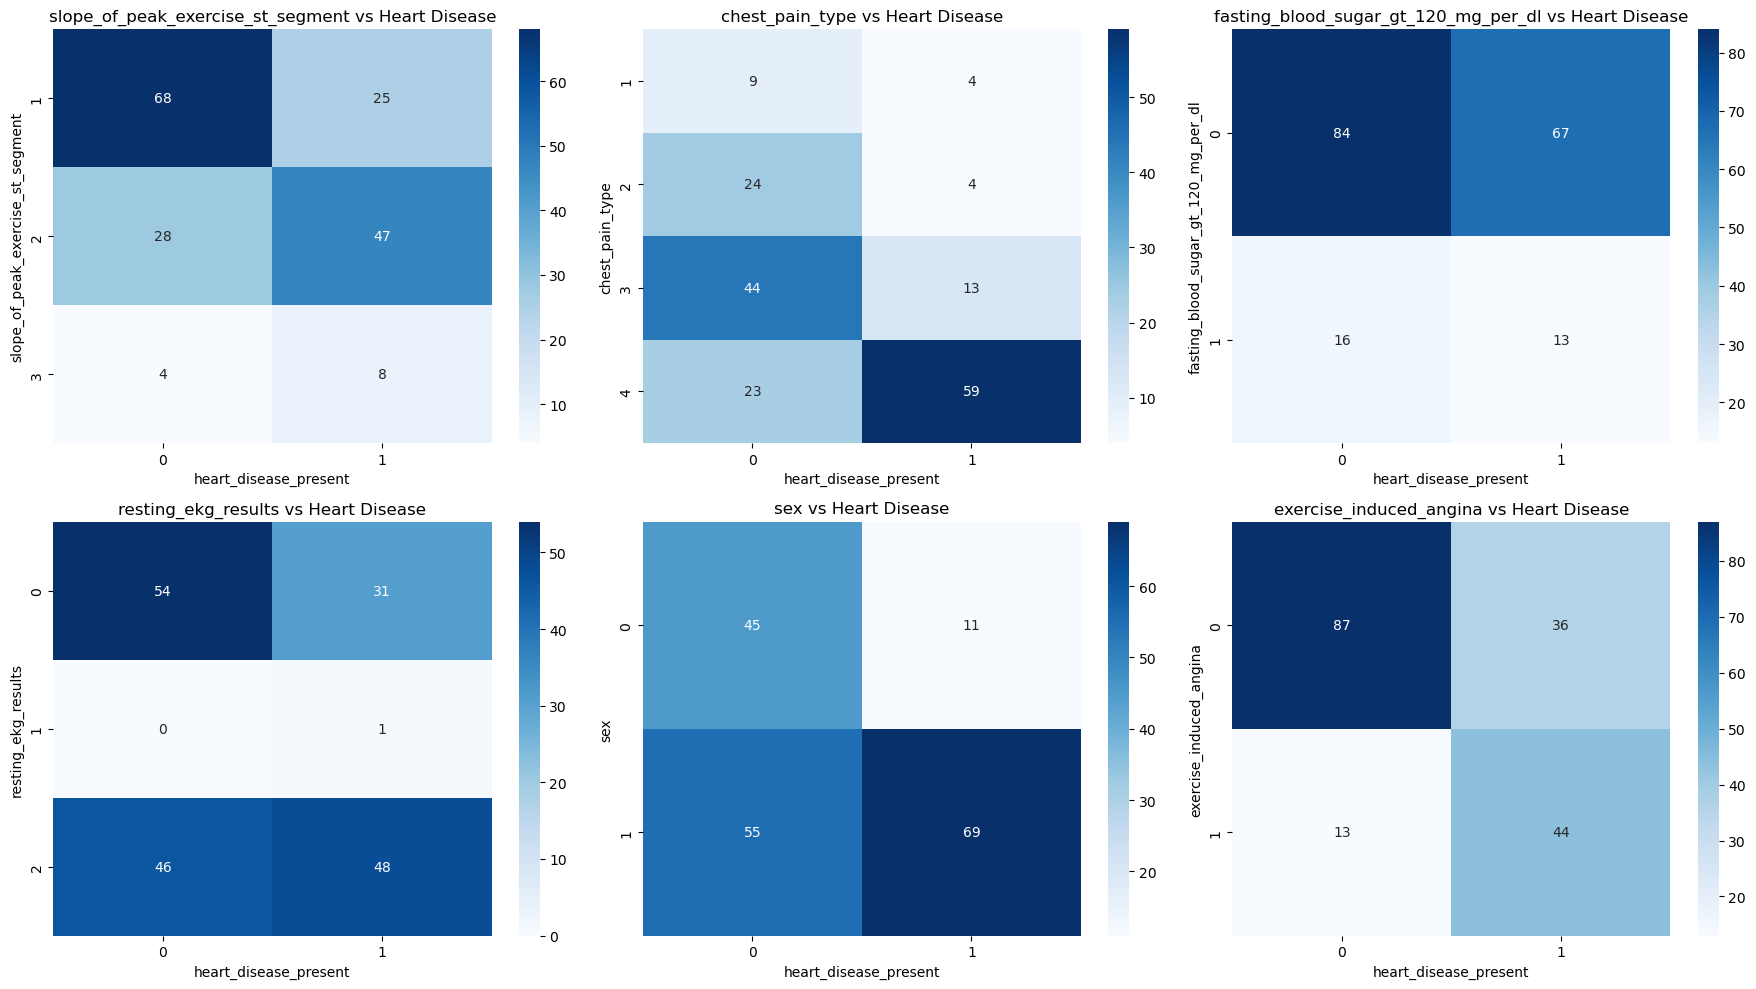

In [34]:
cols = 3
rows = math.ceil(len(cat_cols) / cols)

plt.figure(figsize=(18, 5 * rows))

for i, col in enumerate(cat_cols, 1):
    
    ct = pd.crosstab(
        data[col],
        data['heart_disease_present']
    )

    plt.subplot(rows, cols, i)
    
    sns.heatmap(
        ct,
        annot=True,
        cmap='Blues',
        fmt='d'
    )

    plt.title(f"{col} vs Heart Disease")

plt.tight_layout()
plt.show()

#### Insights:
* Multivariate analysis of categorical features was performed using crosstab heatmaps to study relationships between medical categories and heart disease presence.

* The analysis highlighted how different categorical feature groups were distributed across patients with and without heart disease.

* Certain chest pain types and exercise-induced angina categories appeared more frequently among patients with heart disease.

* Differences were also observed across gender, fasting blood sugar, and resting ECG result categories.

* This analysis provided deeper insights into the combined influence of categorical medical attributes on heart disease prediction.

## Exploratory Data Analysis (EDA) – Key Insights:
* The dataset was clean, with no missing or duplicate values present.

* The target variable showed a relatively balanced distribution between heart disease and non-heart disease cases.

* Numerical feature analysis revealed skewness in serum cholesterol and oldpeak, so log transformation was applied to improve distribution.

* Binary and discrete medical features were not transformed to preserve their medical meaning.

* Several numerical features, including age, cholesterol, maximum heart rate, and oldpeak, showed noticeable relationships with heart disease presence.

* Categorical features such as chest pain type, exercise-induced angina, and resting ECG results also showed associations with heart disease.

* Correlation heatmaps and pairplots helped identify important feature relationships and possible interactions among medical attributes.

* Overall, the analysis identified significant medical features and prepared the dataset effectively for machine learning model development.

# Data Cleaning:

In [35]:
data = data.drop(columns=['patient_id'])

In [36]:
data.head()

,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,1,normal,128,2,0,0,2,5.733341,0.000000,1,45,170,0,0
1,2,normal,110,3,0,0,0,5.370638,0.955511,0,54,158,0,0
2,1,normal,125,4,3,0,2,5.720312,0.000000,1,77,162,1,1
3,1,reversible_defect,152,4,0,0,0,5.411646,0.000000,1,40,181,0,1
4,3,reversible_defect,178,1,0,0,2,5.602119,1.648659,1,59,145,0,0


#### Insights:
Irrelevant features such as patient ID were removed during the data cleaning stage because they do not contribute to heart disease prediction and may introduce unnecessary noise into the model.

# Data Preprocessing Of Numerical Features:

### 1. Feature Scaling:

In [37]:
from sklearn.preprocessing import StandardScaler

num_cols = [
    'resting_blood_pressure',
    'num_major_vessels',
    'serum_cholesterol_mg_per_dl',
    'oldpeak_eq_st_depression',
    'age',
    'max_heart_rate_achieved'
]

scaler = StandardScaler()
data[num_cols] = scaler.fit_transform(data[num_cols])

In [38]:
data[num_cols].describe().T[['mean', 'std']]

,mean,std
resting_blood_pressure,4.835638e-16,1.002789
num_major_vessels,4.440892e-17,1.002789
serum_cholesterol_mg_per_dl,-5.237786e-15,1.002789
oldpeak_eq_st_depression,7.401487e-18,1.002789
age,1.295260e-16,1.002789
max_heart_rate_achieved,6.019876e-16,1.002789


#### Insights:
Before feature scaling, log transformation was applied to highly skewed numerical features to improve their distribution and reduce the impact of extreme values. StandardScaler was then used to standardize the numerical variables, bringing them to a similar scale and helping machine learning models perform more effectively.

# Data Preprocessing Of Categorical Features:

### 1. Encoding:

In [39]:
cat_cols = [
    'slope_of_peak_exercise_st_segment',
    'chest_pain_type',
    'resting_ekg_results'
]

In [40]:
data = pd.get_dummies(data, columns=cat_cols, drop_first=True)

In [41]:
data.dtypes.value_counts()

bool       7
float64    6
int64      4
object     1
Name: count, dtype: int64

In [42]:
data.shape

(180, 18)

In [43]:
data.head()

,thal,resting_blood_pressure,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present,slope_of_peak_exercise_st_segment_2,slope_of_peak_exercise_st_segment_3,chest_pain_type_2,chest_pain_type_3,chest_pain_type_4,resting_ekg_results_1,resting_ekg_results_2
0,normal,-0.195195,-0.718403,0,1.136120,-1.114680,1,-1.053964,0.932485,0,0,False,False,True,False,False,False,True
1,normal,-1.256320,-0.718403,0,-0.640365,0.772626,0,-0.087134,0.387084,0,0,True,False,False,True,False,False,False
2,normal,-0.372049,2.385097,0,1.072302,-1.114680,1,2.383654,0.568884,1,1,False,False,False,False,True,False,True
3,reversible_defect,1.219639,-0.718403,0,-0.439512,-1.114680,1,-1.591092,1.432436,0,1,False,False,False,False,True,False,False
4,reversible_defect,2.752375,-0.718403,0,0.493405,2.141716,1,0.449994,-0.203768,0,0,False,True,False,False,False,False,True


#### Insights:
Categorical feature preprocessing was performed using one-hot encoding to convert categorical medical variables into numerical format suitable for machine learning models. Binary features were kept unchanged, while multi-category features were encoded to preserve meaningful category information and improve model performance.

## Data Preprocessing – Key Insights:
* Initial preprocessing was performed by removing irrelevant features such as patient ID, which do not contribute to heart disease prediction.

* Feature scaling was performed using StandardScaler to standardize numerical variables and bring them to a similar range.

* Categorical features with multiple categories were transformed using one-hot encoding to make them suitable for machine learning algorithms.

* Binary categorical features were kept unchanged since they were already represented in numerical form.

* The preprocessing steps helped improve data quality, model efficiency, and overall predictive performance.

# Feature Engineering:

### 1. Correlation with target:

In [44]:
corr = data.corr(numeric_only=True)

corr['heart_disease_present'].sort_values(ascending=False)

heart_disease_present                   1.000000
chest_pain_type_4                       0.506362
exercise_induced_angina                 0.448647
num_major_vessels                       0.421519
oldpeak_eq_st_depression                0.384051
sex                                     0.335421
slope_of_peak_exercise_st_segment_2     0.309931
resting_ekg_results_2                   0.139271
age                                     0.138255
slope_of_peak_exercise_st_segment_3     0.119523
serum_cholesterol_mg_per_dl             0.096143
resting_ekg_results_1                   0.083566
resting_blood_pressure                  0.078506
fasting_blood_sugar_gt_120_mg_per_dl    0.003379
chest_pain_type_2                      -0.260494
chest_pain_type_3                      -0.296427
max_heart_rate_achieved                -0.375352
Name: heart_disease_present, dtype: float64

### 2. Feature Importance:

In [45]:
print(data['thal'].unique())

['normal' 'reversible_defect' 'fixed_defect']


In [46]:
data['thal'] = data['thal'].astype(str)

In [47]:
data = pd.get_dummies(
    data,
    columns=['thal'],
    drop_first=True
)

In [48]:
print(data.dtypes)

resting_blood_pressure                  float64
num_major_vessels                       float64
fasting_blood_sugar_gt_120_mg_per_dl      int64
serum_cholesterol_mg_per_dl             float64
oldpeak_eq_st_depression                float64
sex                                       int64
age                                     float64
max_heart_rate_achieved                 float64
exercise_induced_angina                   int64
heart_disease_present                     int64
slope_of_peak_exercise_st_segment_2        bool
slope_of_peak_exercise_st_segment_3        bool
chest_pain_type_2                          bool
chest_pain_type_3                          bool
chest_pain_type_4                          bool
resting_ekg_results_1                      bool
resting_ekg_results_2                      bool
thal_normal                                bool
thal_reversible_defect                     bool
dtype: object


In [49]:
from sklearn.ensemble import RandomForestClassifier

X = data.drop('heart_disease_present', axis=1)
y = data['heart_disease_present']

rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

importance.sort_values(
    by='Importance',
    ascending=False
)
print(importance)

                                 Feature  Importance
0                 resting_blood_pressure    0.071150
1                      num_major_vessels    0.089151
2   fasting_blood_sugar_gt_120_mg_per_dl    0.009532
3            serum_cholesterol_mg_per_dl    0.081157
4               oldpeak_eq_st_depression    0.097562
5                                    sex    0.032897
6                                    age    0.090586
7                max_heart_rate_achieved    0.099621
8                exercise_induced_angina    0.062894
9    slope_of_peak_exercise_st_segment_2    0.033597
10   slope_of_peak_exercise_st_segment_3    0.007183
11                     chest_pain_type_2    0.010980
12                     chest_pain_type_3    0.015496
13                     chest_pain_type_4    0.094751
14                 resting_ekg_results_1    0.001982
15                 resting_ekg_results_2    0.020023
16                           thal_normal    0.080447
17                thal_reversible_defect    0.

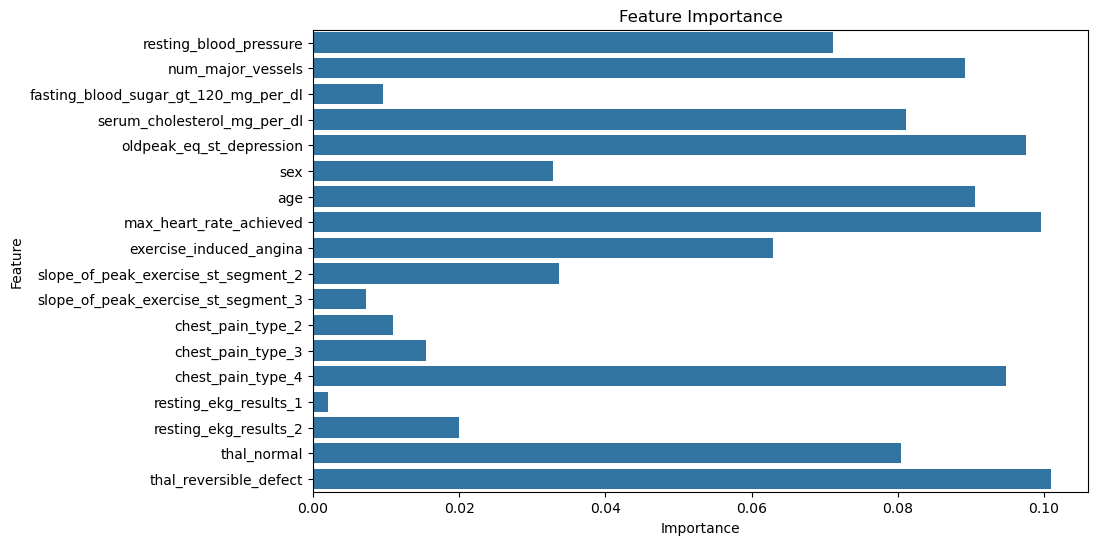

In [50]:
plt.figure(figsize=(10,6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=importance
)

plt.title("Feature Importance")
plt.show()

#### Insights:
Feature engineering was performed to identify the most relevant variables influencing heart disease prediction. Correlation analysis and feature importance techniques helped evaluate the contribution of different medical attributes, enabling better understanding of key predictors before model building.

Additionally, the "thal" feature was encoded during this stage because it had not been fully converted into numerical format during preprocessing, ensuring compatibility with machine learning algorithms.

# Splitting Data For Training And Testing:

In [51]:
X = data.drop('heart_disease_present', axis=1)
y = data['heart_disease_present']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [52]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(144, 18)
(36, 18)
(144,)
(36,)


# Model Building And Evaluation:

### 1. Logistic Regression Model:

In [53]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

### Prediction:

In [54]:
y_pred_lr = lr.predict(X_test)
y_pred_lr

array([0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0])

### Evaluation:

Accuracy: 0.8611111111111112
Precision: 1.0
Recall: 0.75
F1 Score: 0.8571428571428571


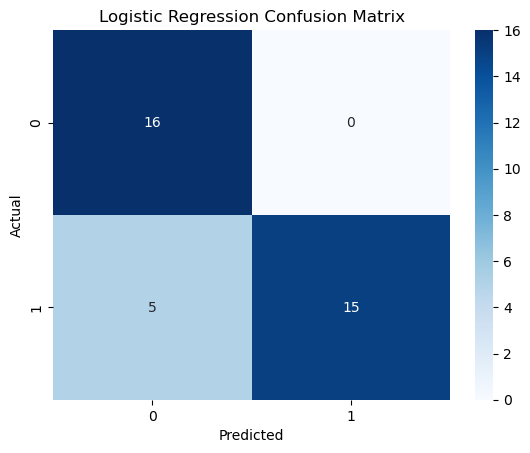

In [55]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))

cm = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

#### Insights:
The Logistic Regression model achieved strong classification performance with an accuracy of approximately 86%. The model showed excellent precision, indicating highly reliable positive predictions, while the recall score suggested that most heart disease cases were successfully identified. The confusion matrix provided a detailed view of the model’s classification performance by showing correctly and incorrectly predicted cases. 

The model achieved a high number of correct predictions, while relatively few cases were misclassified, indicating effective performance in identifying heart disease patients.

### 2. Decision Tree Classifier Model:

In [56]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

### Prediction:

In [57]:
y_pred_dt = dt.predict(X_test)
y_pred_dt

array([0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0])

### Evaluation:

Accuracy: 0.8055555555555556
Precision: 1.0
Recall: 0.65
F1 Score: 0.7878787878787878


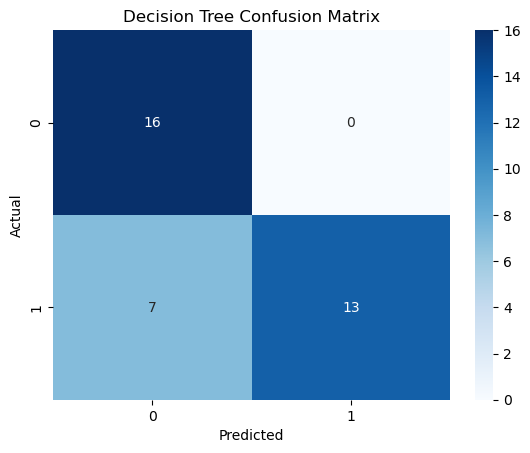

In [58]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))

cm = confusion_matrix(y_test, y_pred_dt)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

#### Insights:
The Decision Tree Classifier achieved an accuracy of approximately 81%, indicating good overall classification performance on the heart disease dataset. The model obtained perfect precision, meaning that all patients predicted as having heart disease were correctly classified. However, the recall score of 65% suggests that some actual heart disease cases were missed by the model. The F1 score demonstrated a reasonable balance between precision and recall, reflecting stable predictive performance overall.

The confusion matrix further illustrated the classification results by showing a high number of correct predictions and a smaller number of misclassifications. While the model was highly accurate in predicting positive heart disease cases, a few patients with actual heart disease were incorrectly classified as non-disease cases. This indicates that although the Decision Tree model performs well, it may not identify all heart disease patients as effectively as desired in a medical prediction scenario.

### 3. Random Forest Classifier Model:

In [59]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

### Prediction:

In [60]:
y_pred_rf = rf.predict(X_test)
y_pred_rf

array([0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0])

### Evaluation:

Accuracy: 0.8611111111111112
Precision: 1.0
Recall: 0.75
F1 Score: 0.8571428571428571


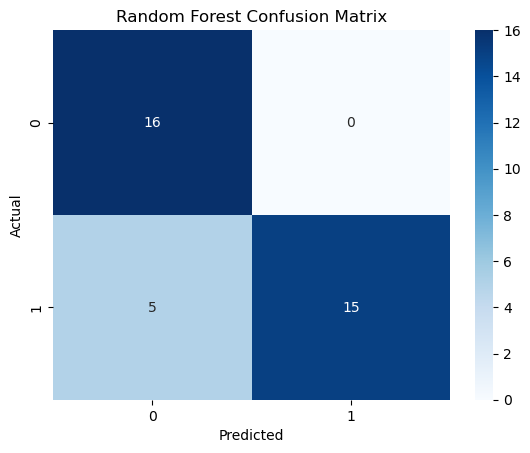

In [61]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

cm = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

#### Insights:
The Logistic Regression and Random Forest models achieved similar evaluation results on the heart disease dataset, indicating that the dataset contains well-structured and informative features for prediction. While Logistic Regression provided a simpler and more interpretable approach, Random Forest demonstrated strong ensemble learning capability. The comparable performance suggests that both models were effective in capturing important patterns related to heart disease prediction.

### 4. Hyperparameter Tuning of Random Forest:

In [62]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train, y_train)

best_rf = grid.best_estimator_

### Prediction:

In [63]:
y_pred_tuned = best_rf.predict(X_test)
y_pred_tuned

array([0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0,
       1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0])

### Evaluation

Accuracy: 0.8333333333333334
Precision: 0.9375
Recall: 0.75
F1 Score: 0.8333333333333334


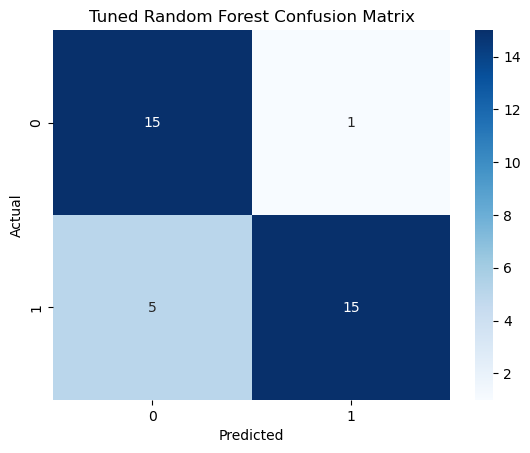

In [65]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("F1 Score:", f1_score(y_test, y_pred_tuned))

cm = confusion_matrix(y_test, y_pred_tuned)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned Random Forest Confusion Matrix")

plt.show()

#### Insights:
Hyperparameter tuning was performed on the Random Forest Classifier to optimize model performance by selecting the best parameter combinations. The tuned model achieved an accuracy of approximately 83%, with high precision and a balanced F1 score, indicating strong classification capability. The recall score showed that the model successfully identified most heart disease cases, although a few positive cases were still missed during prediction.

The confusion matrix demonstrated that the tuned Random Forest model correctly classified the majority of patients while producing relatively few misclassifications. Compared to the original Random Forest model, the tuned model showed slightly lower overall accuracy and F1 score, although it still maintained strong predictive performance. This indicates that the default Random Forest model performed slightly better on this dataset, while hyperparameter tuning provided a more optimized and controlled model configuration.

# Model Comparison and Final Selection:

Different machine learning models were implemented and evaluated for heart disease prediction, including Logistic Regression, Decision Tree Classifier, Random Forest Classifier, and Hyperparameter Tuned Random Forest. The models were compared using evaluation metrics such as accuracy, precision, recall, and F1 score to determine their overall predictive performance.

Among all models, Logistic Regression and Random Forest Classifier achieved the highest accuracy and F1 score, demonstrating strong and reliable performance on the dataset. The Decision Tree model showed comparatively lower recall, indicating that it missed more heart disease cases. Although hyperparameter tuning optimized the Random Forest model configuration, its performance was slightly lower than the default Random Forest model on this dataset.

Based on the evaluation results, the Random Forest Classifier was selected as the final model because of its strong overall performance, ability to handle complex feature relationships, and stable classification capability for heart disease prediction.

# Conclusion:

The Heart Disease Prediction project was successfully developed using machine learning techniques to analyze medical attributes and predict the presence of heart disease. Exploratory Data Analysis helped identify important patterns, relationships, and feature distributions within the dataset, while preprocessing techniques such as log transformation, feature scaling, and categorical encoding improved data quality and model readiness.

Multiple machine learning models, including Logistic Regression, Decision Tree Classifier, Random Forest Classifier, and Hyperparameter Tuned Random Forest, were implemented and evaluated using accuracy, precision, recall, F1 score, and confusion matrices. Among all models, the Random Forest Classifier demonstrated the best overall performance and was selected as the final model for heart disease prediction.

The project highlights the potential of machine learning in assisting early heart disease detection and supporting healthcare decision-making. Accurate prediction models can help healthcare professionals identify high-risk patients at an earlier stage, enabling timely treatment and reducing the risk of severe cardiac complications.

# Suggestions to Hospitals for Preventing Heart Disease Risks:

Hospitals should encourage regular cardiovascular health screenings, especially for patients with high-risk factors such as high cholesterol, abnormal blood pressure, chest pain, and exercise-induced angina. Early identification of heart disease through predictive models can help doctors provide timely treatment and reduce the risk of severe cardiac complications.

Healthcare institutions should also promote awareness programs related to healthy lifestyle habits, including balanced nutrition, regular physical activity, stress management, and smoking cessation. Integrating machine learning-based heart disease prediction systems into hospital decision-making processes can further support early diagnosis, improve patient monitoring, and help prevent life-threatening conditions.

# Challenges Faced and Techniques Used:

During the development of the Heart Disease Prediction project, several challenges were encountered while analyzing and preprocessing the dataset. One major challenge was the presence of skewed numerical features such as serum cholesterol and oldpeak values. Highly skewed data can negatively affect model performance and reduce the effectiveness of certain machine learning algorithms. To address this issue, log transformation was applied to the skewed features in order to improve their distribution and reduce the impact of extreme values.

Another challenge involved handling numerical features with different value ranges, which could lead to biased model learning where features with larger scales dominate others. To solve this problem, StandardScaler was used to standardize the numerical variables and bring them to a similar scale. This preprocessing step improved model stability and helped algorithms learn more effectively.

The dataset also contained categorical variables that machine learning models could not process directly. One-hot encoding was applied to convert categorical features into numerical format suitable for model training. Additionally, the thal feature was identified as remaining in object format during feature engineering, so it was separately encoded to ensure compatibility with machine learning algorithms.

Another challenge was the presence of outliers in medical attributes such as cholesterol, resting blood pressure, and oldpeak values. Since this is a healthcare dataset, these outliers could represent genuine patient conditions rather than errors. Instead of removing them directly, careful analysis was performed and preprocessing techniques such as log transformation and scaling were used to minimize their impact while preserving important medical information.

Finally, selecting the most effective machine learning model was an important challenge. Multiple models including Logistic Regression, Decision Tree Classifier, Random Forest Classifier, and Hyperparameter Tuned Random Forest were implemented and compared using evaluation metrics such as accuracy, precision, recall, F1 score, and confusion matrix analysis. Based on the results, the Random Forest Classifier was selected as the final model due to its strong and stable predictive performance.